<a href="https://colab.research.google.com/github/fernandofilgueiras-ctrl/MVP_Analise_de_Evasao_Escolar/blob/main/MVP_Fernando_Filgueiras_evasao_academica_preprocessamento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MBA EM CIÊNCIA DE DADOS E INTELIGÊNCIA ARTIFICIAL**

# **MVP - ANÁLISE DE DADOS E BOAS PRÁTICAS**

Discente: Fernando de Barros Filgueiras

Tema: Predição de evasão e sucesso acadêmico no ensino superior.

# Predição de evasão e sucesso acadêmico no ensino superior

Este notebook documenta, em formato de relatório, as etapas iniciais de um projeto de aprendizado de máquina voltado à predição de evasão e sucesso acadêmico de estudantes de graduação. O percurso cobre a definição do problema, a análise exploratória dos dados e o pré-processamento, encerrando com a disponibilização para download das visões processadas do conjunto de dados. Nenhum modelo é treinado. O trabalho termina na preparação dos dados.

O conjunto de dados utilizado provém de uma instituição de ensino superior e foi construído a partir da integração de diversas bases administrativas e acadêmicas. Ele reúne informações disponíveis no momento da matrícula (trajetória acadêmica anterior, dados demográficos e fatores socioeconômicos), indicadores macroeconômicos do período de ingresso e o desempenho dos estudantes ao final do primeiro e do segundo semestres letivos. O conjunto está descrito em Realinho et al. (2022) e é distribuído pelo repositório de aprendizado de máquina da UCI sob a licença Creative Commons Atribuição 4.0 (CC BY 4.0).

**Fonte.** Realinho, V., Machado, J., Baptista, L., e Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146

# 1. Definição do problema

## 1.1 Descrição do problema

A evasão no ensino superior constitui um problema relevante tanto para as instituições de ensino quanto para as políticas públicas educacionais. A saída prematura de estudantes representa perda de investimento público e privado, frustração de trajetórias individuais e redução da eficiência do sistema. Identificar precocemente os estudantes em risco permite que a instituição direcione ações de apoio acadêmico, financeiro e pedagógico antes que o abandono se consume.

O problema que este projeto aborda consiste em compreender, a partir das informações conhecidas no ingresso e do desempenho nos dois primeiros semestres, quais características se associam à situação do estudante ao final do prazo regular do curso, e em preparar os dados para uma futura tarefa de predição dessa situação. A variável alvo (`Target`) assume três categorias. A categoria **Dropout** designa estudantes que abandonaram o curso. A categoria **Graduate** designa estudantes que concluíram o curso no prazo regular. A categoria **Enrolled** designa estudantes que, ao final do prazo regular, permaneciam matriculados sem terem concluído o curso.

**Unidade de observação.** Cada linha do conjunto representa um estudante em uma matrícula de graduação, descrito pelas informações do ingresso, pelo desempenho nos dois primeiros semestres e pela situação ao final do prazo regular do curso. A base não contém identificador do estudante, de modo que a linha é a única chave disponível.

## 1.2 Aprendizado supervisionado ou não supervisionado

O objetivo analítico deste notebook é exploratório e preparatório. Ele descreve os dados, examina as hipóteses abaixo e entrega conjuntos prontos para modelagem, sem treinar modelos. O uso preditivo futuro para o qual os dados são preparados é de **aprendizado supervisionado**, na forma de uma **classificação multiclasse com três categorias**, cujo alvo é a coluna `Target`. Cada instância está rotulada com a situação final do estudante, e a variável alvo é categórica, o que caracteriza classificação e não regressão. A documentação do conjunto no repositório UCI registra desequilíbrio entre as classes, aspecto verificado empiricamente na seção 3.2.1.

## 1.3 Premissas e hipóteses

A construção do projeto parte de algumas premissas e hipóteses de trabalho que a análise exploratória examina.

H1: A primeira hipótese é que o desempenho nos dois primeiros semestres, expresso pelo número de unidades curriculares aprovadas e pela nota média, reúne os atributos mais fortemente associados à situação final. Espera-se que estudantes com poucas aprovações e notas baixas no primeiro ano apresentem proporção muito maior de evasão.

H2: A segunda hipótese diz respeito aos fatores financeiros. Espera-se que a regularidade no pagamento das mensalidades, a condição de devedor e a titularidade de bolsa de estudos se associem fortemente à permanência.

H3: A terceira hipótese relaciona-se ao perfil demográfico. Espera-se maior proporção de evasão entre estudantes que ingressam em idade mais avançada, por vias de acesso não convencionais ou em cursos noturnos, perfil que frequentemente concilia estudo e trabalho.

H4: Uma quarta hipótese, de natureza metodológica, é que a classe **Enrolled** será a mais difícil de separar das demais, uma vez que representa uma situação intermediária e heterogênea, que inclui tanto estudantes com atraso moderado quanto estudantes em trajetória de abandono ainda não formalizada. Como este trabalho não treina modelos, H4 só pode ser examinada de forma indireta, pela sobreposição das distribuições dessa classe com as das outras duas.

Assume-se ainda, como premissa, que o conjunto de dados é representativo da população de estudantes da instituição no período coberto e que a rotulagem da variável alvo foi feita de maneira consistente. As análises são descritivas. As associações encontradas não são tratadas como relações causais.

## 1.4 Restrições e condições impostas na seleção dos dados

**Fonte e versão.** Realinho, V., Vieira Martins, M., Machado, J. e Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [conjunto de dados]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success (DOI https://doi.org/10.24432/C5MC89). O arquivo utilizado é o `data.csv` distribuído pelo repositório, na versão doada em 12 de dezembro de 2021.

**Período e população.** Segundo o artigo que descreve o conjunto (Realinho et al., 2022), os registros referem-se a estudantes de 17 cursos de graduação de uma instituição de ensino superior portuguesa, matriculados entre os anos letivos de 2008/2009 e 2018/2019. Os autores são vinculados ao Instituto Politécnico de Portalegre. A variável alvo foi definida com base no prazo regular de conclusão do curso, o que explica a existência da categoria intermediária **Enrolled**.

**Recortes.** Nenhum recorte de linhas ou de colunas foi feito neste trabalho. As 4424 linhas e as 37 colunas do arquivo original são utilizadas integralmente. A página do repositório informa que os autores realizaram um pré-processamento para tratar anomalias, valores discrepantes inexplicáveis e valores ausentes, sem detalhar quantos registros foram afetados.

**Condições de uso.** O conjunto é distribuído sob a licença Creative Commons Atribuição 4.0 Internacional (CC BY 4.0), que permite uso e redistribuição com atribuição aos autores. Os dados foram anonimizados na origem e não contêm identificadores pessoais.

As variáveis categóricas foram codificadas numericamente conforme as tabelas de domínio dos sistemas administrativos da instituição, e os dicionários de códigos estão documentados na publicação original. Essa codificação numérica de variáveis nominais exige cuidado na etapa de pré-processamento, para que códigos arbitrários não sejam tratados como magnitudes.

## 1.5 Definição dos atributos

O conjunto de dados possui 36 atributos preditores e 1 variável alvo. A tabela a seguir descreve cada atributo, seu tipo semântico, sua unidade ou escala e o momento em que a informação se torna disponível.

| Atributo | Descrição | Tipo semântico | Momento |
|---|---|---|---|
| Marital status | Estado civil do estudante (1 solteiro, 2 casado, 3 viúvo, 4 divorciado, 5 união de fato, 6 separado judicialmente) | Categórico nominal | Matrícula |
| Application mode | Via de ingresso no curso (concurso geral, contingentes especiais, maiores de 23 anos, transferência, mudança de curso, entre outras) | Categórico nominal | Matrícula |
| Application order | Ordem de preferência em que o curso foi escolhido na candidatura (0 primeira opção até 9 última opção) | Ordinal | Matrícula |
| Course | Curso de graduação em que o estudante se matriculou (17 cursos, codificados numericamente) | Categórico nominal | Matrícula |
| Daytime/evening attendance | Regime de frequência (1 diurno, 0 noturno) | Binário | Matrícula |
| Previous qualification | Nível de escolaridade anterior ao ingresso (ensino secundário, bacharelado, licenciatura, mestrado, cursos técnicos, entre outros) | Categórico nominal | Matrícula |
| Previous qualification (grade) | Nota obtida na qualificação anterior (escala de 0 a 200) | Numérico contínuo | Matrícula |
| Nacionality | Nacionalidade do estudante (codificada numericamente) | Categórico nominal | Matrícula |
| Mother's qualification | Escolaridade da mãe (codificada numericamente) | Categórico nominal | Matrícula |
| Father's qualification | Escolaridade do pai (codificada numericamente) | Categórico nominal | Matrícula |
| Mother's occupation | Ocupação da mãe (codificada numericamente) | Categórico nominal | Matrícula |
| Father's occupation | Ocupação do pai (codificada numericamente) | Categórico nominal | Matrícula |
| Admission grade | Nota de admissão no curso (escala de 0 a 200) | Numérico contínuo | Matrícula |
| Displaced | Indica se o estudante é deslocado, isto é, se reside fora da região da instituição (1 sim, 0 não) | Binário | Matrícula |
| Educational special needs | Indica se o estudante possui necessidades educacionais especiais (1 sim, 0 não) | Binário | Matrícula |
| Debtor | Indica se o estudante possui débitos com a instituição (1 sim, 0 não) | Binário | Matrícula |
| Tuition fees up to date | Indica se as mensalidades estão em dia (1 sim, 0 não) | Binário | Matrícula |
| Gender | Sexo do estudante (1 masculino, 0 feminino) | Binário | Matrícula |
| Scholarship holder | Indica se o estudante é bolsista (1 sim, 0 não) | Binário | Matrícula |
| Age at enrollment | Idade do estudante no momento da matrícula, em anos | Numérico discreto | Matrícula |
| International | Indica se o estudante é internacional (1 sim, 0 não) | Binário | Matrícula |
| Curricular units 1st sem (credited) | Número de unidades curriculares creditadas no primeiro semestre | Numérico discreto | Fim do 1º semestre |
| Curricular units 1st sem (enrolled) | Número de unidades curriculares em que o estudante se inscreveu no primeiro semestre | Numérico discreto | Fim do 1º semestre |
| Curricular units 1st sem (evaluations) | Número de avaliações realizadas no primeiro semestre | Numérico discreto | Fim do 1º semestre |
| Curricular units 1st sem (approved) | Número de unidades curriculares aprovadas no primeiro semestre | Numérico discreto | Fim do 1º semestre |
| Curricular units 1st sem (grade) | Nota média no primeiro semestre (escala de 0 a 20) | Numérico contínuo | Fim do 1º semestre |
| Curricular units 1st sem (without evaluations) | Número de unidades curriculares sem avaliação no primeiro semestre | Numérico discreto | Fim do 1º semestre |
| Curricular units 2nd sem (credited) | Número de unidades curriculares creditadas no segundo semestre | Numérico discreto | Fim do 2º semestre |
| Curricular units 2nd sem (enrolled) | Número de unidades curriculares em que o estudante se inscreveu no segundo semestre | Numérico discreto | Fim do 2º semestre |
| Curricular units 2nd sem (evaluations) | Número de avaliações realizadas no segundo semestre | Numérico discreto | Fim do 2º semestre |
| Curricular units 2nd sem (approved) | Número de unidades curriculares aprovadas no segundo semestre | Numérico discreto | Fim do 2º semestre |
| Curricular units 2nd sem (grade) | Nota média no segundo semestre (escala de 0 a 20) | Numérico contínuo | Fim do 2º semestre |
| Curricular units 2nd sem (without evaluations) | Número de unidades curriculares sem avaliação no segundo semestre | Numérico discreto | Fim do 2º semestre |
| Unemployment rate | Taxa de desemprego do país no ano de ingresso (%) | Numérico contínuo | Contexto macroeconômico |
| Inflation rate | Taxa de inflação do país no ano de ingresso (%) | Numérico contínuo | Contexto macroeconômico |
| GDP | Variação do PIB do país no ano de ingresso (%) | Numérico contínuo | Contexto macroeconômico |
| Target | Situação final do estudante (Dropout, Enrolled, Graduate) | Categórico nominal (alvo) | Fim do prazo regular |

**Códigos, identificadores e valores que representam ausência.** Vários atributos nominais (curso, via de ingresso, nacionalidade, escolaridade e ocupação dos pais) estão representados por códigos inteiros sem qualquer ordem subjacente. Caso fossem tratados como variáveis numéricas, o curso de código 9991 seria interpretado como "maior" que o curso de código 33, o que não faz sentido. Não há coluna identificadora do estudante. Não há valores nulos explícitos, mas a análise da seção 3.1.3 mostra que o valor 0 funciona como marcador de ausência em duas situações. A primeira ocorre nas notas semestrais (`Curricular units ... (grade)`) quando o estudante não realizou nenhuma avaliação no semestre. A segunda ocorre em todas as contagens de unidades curriculares dos 180 registros de um mesmo curso (código 171) para os quais não há nenhuma inscrição registrada no primeiro ano.

**Atributos derivados.** A seção 4.1 acrescenta seis atributos calculados a partir dos originais.

| Atributo derivado | Descrição | Tipo semântico | Unidade ou escala |
|---|---|---|---|
| no_evaluations_1st_sem | Indica ausência de avaliações no primeiro semestre (1 sim, 0 não) | Binário | Adimensional |
| no_evaluations_2nd_sem | Indica ausência de avaliações no segundo semestre (1 sim, 0 não) | Binário | Adimensional |
| approval_rate_1st_sem | Unidades aprovadas divididas pelas inscritas no primeiro semestre (0 quando não há inscrição) | Numérico contínuo | Proporção de 0 a 1 |
| approval_rate_2nd_sem | Unidades aprovadas divididas pelas inscritas no segundo semestre (0 quando não há inscrição) | Numérico contínuo | Proporção de 0 a 1 |
| mean_grade_first_year | Média simples das notas dos dois semestres | Numérico contínuo | Escala de 0 a 20 |
| approved_change | Aprovações do segundo semestre menos aprovações do primeiro | Numérico discreto | Unidades curriculares |

# 2. Configuração do ambiente e carga dos dados

Nesta seção são importadas as bibliotecas necessárias e é realizada a carga do arquivo de dados. O notebook foi escrito para o ambiente Google Colab e lê o conjunto de dados diretamente do Google Drive. O Drive é montado no ambiente de execução e o arquivo CSV é localizado na pasta `Análise de Dados II`. Caso a pasta não seja encontrada em "Meu Drive" (por exemplo, se ela estiver apenas em "Compartilhados comigo"), o notebook recorre ao download direto da pasta compartilhada pelo link, de modo que a execução prossegue sem intervenção manual. Fora do Colab, basta posicionar o arquivo `data.csv` no mesmo diretório do notebook.

As bibliotecas escolhidas são as de uso consolidado em ciência de dados em Python. A biblioteca `pandas` é utilizada para manipulação tabular, `numpy` para operações numéricas, `matplotlib` e `seaborn` para visualização e `scikit-learn` para as transformações de pré-processamento.

In [1]:
# Bibliotecas de uso geral
import os
import re
import sys
import zipfile

# Bibliotecas de manipulação e análise de dados
import numpy as np
import pandas as pd

# Bibliotecas de visualização
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas de pré-processamento
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif

# Configurações gerais
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Semente para reprodutibilidade
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paleta fixa para as classes da variável alvo, usada em todos os gráficos
CLASS_ORDER = ["Dropout", "Enrolled", "Graduate"]
CLASS_COLORS = {"Dropout": "#D55E00", "Enrolled": "#E69F00", "Graduate": "#0072B2"}

In [2]:
# Versões das dependências relevantes no ambiente de execução
versoes = {
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
}
pd.Series(versoes, name="versão").to_frame()

,versão
python,3.13.18
pandas,2.2.3
numpy,2.4.6
scikit-learn,1.6.1
matplotlib,3.10.0
seaborn,0.13.2


In [3]:
# Carga do arquivo de dados a partir do Google Drive.
# O arquivo original utiliza ponto e vírgula como separador e possui marca de ordem de bytes (BOM) no início.
PASTA_DRIVE = "Análise de Dados II"
ID_PASTA_COMPARTILHADA = "12rBThrOTVUfS3rzNA5e63Rj5KyYjq5vD"
DATA_FILE = "data.csv"


def carregar_dados(caminho):
    '''Lê o arquivo CSV com o separador e a codificação corretos.'''
    return pd.read_csv(caminho, sep=";", encoding="utf-8-sig")


def localizar_pasta(raiz, nome_pasta):
    '''Percorre a árvore do Drive montado e retorna o caminho da primeira pasta com o nome indicado.'''
    for atual, subpastas, _ in os.walk(raiz):
        if nome_pasta in subpastas:
            return os.path.join(atual, nome_pasta)
    return None


def escolher_csv(pasta):
    '''Retorna o CSV da pasta, priorizando nomes que contenham "data" ou "dados".'''
    csvs = sorted(f for f in os.listdir(pasta) if f.lower().endswith(".csv"))
    if not csvs:
        raise FileNotFoundError(f"Nenhum arquivo CSV encontrado em {pasta}.")
    preferidos = [f for f in csvs if "data" in f.lower() or "dados" in f.lower()]
    return os.path.join(pasta, (preferidos or csvs)[0])


def obter_caminho_dados():
    '''Monta o Google Drive e localiza o arquivo de dados; fora do Colab, usa o arquivo local.'''
    try:
        from google.colab import drive  # disponível apenas no Colab
    except ImportError:
        if os.path.exists(DATA_FILE):
            print("Ambiente fora do Colab. Utilizando o arquivo local.")
            return DATA_FILE
        raise FileNotFoundError("Coloque o arquivo data.csv no mesmo diretório deste notebook.")

    drive.mount("/content/drive", force_remount=False)
    pasta = localizar_pasta("/content/drive/MyDrive", PASTA_DRIVE)
    if pasta is not None:
        print(f"Pasta encontrada no Drive: {pasta}")
        return escolher_csv(pasta)

    # A pasta não está em "Meu Drive". Faz o download da pasta compartilhada pelo link.
    print("Pasta não encontrada em Meu Drive. Realizando download da pasta compartilhada.")
    import gdown
    destino = "/content/dados_drive"
    gdown.download_folder(id=ID_PASTA_COMPARTILHADA, output=destino, quiet=True)
    return escolher_csv(destino)


caminho_dados = obter_caminho_dados()
print(f"Arquivo de dados utilizado: {caminho_dados}")

df_raw = carregar_dados(caminho_dados)
print(f"Dimensões do conjunto de dados: {df_raw.shape[0]} instâncias e {df_raw.shape[1]} atributos.")

Mounted at /content/drive
Pasta não encontrada em Meu Drive. Realizando download da pasta compartilhada.
Arquivo de dados utilizado: /content/dados_drive/data.csv
Dimensões do conjunto de dados: 4424 instâncias e 37 atributos.


## 2.1 Padronização dos nomes dos atributos

Os nomes originais das colunas contêm espaços, parênteses, apóstrofos e, em um caso, um caractere de tabulação residual ao final do nome (`Daytime/evening attendance\t`). Esses detalhes dificultam o acesso programático às colunas e podem gerar erros silenciosos. Por isso, os nomes são convertidos para o padrão `snake_case`, sem caracteres especiais. O erro ortográfico em `Nacionality` é corrigido para `nationality`. Um dicionário de correspondência entre os nomes originais e os novos é mantido para referência.

In [4]:
def padronizar_nome(nome):
    '''Converte um nome de coluna para snake_case sem caracteres especiais.'''
    nome = nome.strip().lower()
    nome = nome.replace("nacionality", "nationality")
    nome = nome.replace("'", "")
    nome = re.sub(r"[^a-z0-9]+", "_", nome)
    return nome.strip("_")


df = df_raw.copy()
mapa_nomes = {col: padronizar_nome(col) for col in df.columns}
df = df.rename(columns=mapa_nomes)

# Abreviação dos nomes longos das unidades curriculares para facilitar leitura dos gráficos
df.columns = [c.replace("curricular_units_", "cu_") for c in df.columns]
mapa_nomes = {k: v.replace("curricular_units_", "cu_") for k, v in mapa_nomes.items()}

pd.DataFrame({"nome_original": mapa_nomes.keys(), "nome_padronizado": mapa_nomes.values()})

,nome_original,nome_padronizado
0,Marital status,marital_status
1,Application mode,application_mode
2,Application order,application_order
3,Course,course
4,Daytime/evening attendance\t,daytime_evening_attendance
5,Previous qualification,previous_qualification
6,Previous qualification (grade),previous_qualification_grade
7,Nacionality,nationality
8,Mother's qualification,mothers_qualification
9,Father's qualification,fathers_qualification


# 3. Análise exploratória de dados

O objetivo desta seção é compreender a informação disponível antes de qualquer transformação. A análise é organizada em duas partes. A primeira apresenta estatísticas descritivas, com atenção aos tipos de dados, aos valores ausentes e às inconsistências. A segunda apresenta visualizações da distribuição dos atributos, da distribuição das classes e das relações entre atributos e variável alvo. Após cada gráfico, um parágrafo sintetiza os achados e os pontos de atenção.

## 3.1 Estatísticas descritivas

### 3.1.1 Quantidade de atributos e instâncias e tipos de dados

In [5]:
print(f"Número de instâncias: {df.shape[0]}")
print(f"Número de atributos (incluindo a variável alvo): {df.shape[1]}")
print()
print("Contagem de colunas por tipo de dado inferido pelo pandas:")
print(df.dtypes.value_counts())

Número de instâncias: 4424
Número de atributos (incluindo a variável alvo): 37

Contagem de colunas por tipo de dado inferido pelo pandas:
int64      29
float64     7
object      1
Name: count, dtype: int64


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   marital_status                  4424 non-null   int64  
 1   application_mode                4424 non-null   int64  
 2   application_order               4424 non-null   int64  
 3   course                          4424 non-null   int64  
 4   daytime_evening_attendance      4424 non-null   int64  
 5   previous_qualification          4424 non-null   int64  
 6   previous_qualification_grade    4424 non-null   float64
 7   nationality                     4424 non-null   int64  
 8   mothers_qualification           4424 non-null   int64  
 9   fathers_qualification           4424 non-null   int64  
 10  mothers_occupation              4424 non-null   int64  
 11  fathers_occupation              4424 non-null   int64  
 12  admission_grade                 44

O conjunto possui 4424 instâncias e 37 colunas. O `pandas` inferiu 29 colunas inteiras, 7 colunas de ponto flutuante e 1 coluna textual (a variável alvo). Essa inferência, contudo, reflete apenas a representação de armazenamento e não o tipo semântico dos atributos. Como discutido na definição do problema, muitas colunas inteiras são na verdade códigos de categorias nominais. A classificação semântica dos atributos é formalizada a seguir, pois ela orienta tanto a análise exploratória quanto o pré-processamento.

In [7]:
# Classificação semântica dos atributos, definida a partir da documentação do conjunto de dados
TARGET = "target"

ATRIBUTOS_NOMINAIS = [
    "marital_status", "application_mode", "course", "previous_qualification",
    "nationality", "mothers_qualification", "fathers_qualification",
    "mothers_occupation", "fathers_occupation",
]

ATRIBUTOS_BINARIOS = [
    "daytime_evening_attendance", "displaced", "educational_special_needs",
    "debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder", "international",
]

ATRIBUTOS_ORDINAIS = ["application_order"]

ATRIBUTOS_NUMERICOS = [
    "previous_qualification_grade", "admission_grade", "age_at_enrollment",
    "cu_1st_sem_credited", "cu_1st_sem_enrolled", "cu_1st_sem_evaluations",
    "cu_1st_sem_approved", "cu_1st_sem_grade", "cu_1st_sem_without_evaluations",
    "cu_2nd_sem_credited", "cu_2nd_sem_enrolled", "cu_2nd_sem_evaluations",
    "cu_2nd_sem_approved", "cu_2nd_sem_grade", "cu_2nd_sem_without_evaluations",
    "unemployment_rate", "inflation_rate", "gdp",
]

# Verificação de que todas as colunas foram classificadas
classificados = set(ATRIBUTOS_NOMINAIS + ATRIBUTOS_BINARIOS + ATRIBUTOS_ORDINAIS + ATRIBUTOS_NUMERICOS + [TARGET])
assert classificados == set(df.columns), set(df.columns) ^ classificados

print(f"Nominais: {len(ATRIBUTOS_NOMINAIS)} | Binários: {len(ATRIBUTOS_BINARIOS)} | "
      f"Ordinais: {len(ATRIBUTOS_ORDINAIS)} | Numéricos: {len(ATRIBUTOS_NUMERICOS)} | Alvo: 1")

Nominais: 9 | Binários: 8 | Ordinais: 1 | Numéricos: 18 | Alvo: 1


### 3.1.2 Primeiras linhas do conjunto de dados

In [8]:
df.head(10)

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,cu_1st_sem_credited,cu_1st_sem_enrolled,cu_1st_sem_evaluations,cu_1st_sem_approved,cu_1st_sem_grade,cu_1st_sem_without_evaluations,cu_2nd_sem_credited,cu_2nd_sem_enrolled,cu_2nd_sem_evaluations,cu_2nd_sem_approved,cu_2nd_sem_grade,cu_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,39,1,9991,0,19,133.1,1,37,37,9,7,114.8,0,0,1,1,1,0,50,0,0,5,10,5,11.857143,0,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,9500,1,1,142.0,1,19,38,7,10,128.4,1,0,0,1,0,1,18,0,0,7,9,7,13.300000,0,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,18,4,9254,1,1,119.0,1,37,37,9,9,113.1,1,0,0,0,1,0,22,0,0,5,5,0,0.000000,0,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,9238,1,1,137.0,62,1,1,9,9,129.3,0,0,0,1,0,1,21,1,0,6,8,6,13.875000,0,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,9238,1,1,138.0,1,1,19,4,7,123.0,1,0,1,0,0,0,18,0,0,6,9,5,11.400000,0,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


A inspeção das primeiras linhas confirma várias características antecipadas. Os atributos nominais aparecem como inteiros, inclusive com códigos de grande magnitude no caso do curso (por exemplo, 9254 e 9773), o que reforça a necessidade de tratá-los como categorias. Chama a atenção, já na primeira linha, um estudante com zero unidades curriculares inscritas, zero avaliações e nota zero em ambos os semestres, classificado como **Dropout**. Esse padrão sugere que parte dos evadidos abandonou o curso antes mesmo de iniciar as atividades acadêmicas, e que o valor zero na nota, nesses casos, não representa um desempenho avaliado, mas a ausência de avaliação. Esse ponto será examinado com cuidado na verificação de inconsistências.

Observa-se também que as notas de qualificação anterior e de admissão estão em escala de 0 a 200, enquanto as notas semestrais estão em escala de 0 a 20. A coexistência de escalas distintas é um indicativo da necessidade de padronização ou normalização para algoritmos sensíveis à escala.

### 3.1.3 Valores faltantes, duplicados, discrepantes e inconsistentes

In [9]:
faltantes = df.isna().sum()
print(f"Total de valores faltantes explícitos (NaN): {faltantes.sum()}")
print(f"Colunas com valores faltantes: {list(faltantes[faltantes > 0].index) or 'nenhuma'}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")

Total de valores faltantes explícitos (NaN): 0
Colunas com valores faltantes: nenhuma
Linhas duplicadas: 0


Não há valores faltantes explícitos nem linhas duplicadas. Esse resultado, embora positivo, merece cautela. Em bases administrativas, a ausência de informação costuma ser codificada por valores sentinela, como zero, em vez de valores nulos. Por isso, é necessário investigar se há valores faltantes **implícitos**. Os candidatos mais evidentes são as notas semestrais iguais a zero, que podem significar ausência de avaliação e não nota zero efetiva.

In [10]:
def resumir_zeros_semestre(df, sem):
    '''Resume a relação entre nota zero e ausência de avaliações em um semestre.'''
    nota_zero = df[f"cu_{sem}_grade"] == 0
    sem_avaliacoes = df[f"cu_{sem}_evaluations"] == 0
    sem_inscricao = df[f"cu_{sem}_enrolled"] == 0
    return pd.Series({
        "instâncias com nota zero": int(nota_zero.sum()),
        "   das quais sem nenhuma avaliação": int((nota_zero & sem_avaliacoes).sum()),
        "   das quais sem nenhuma inscrição": int((nota_zero & sem_inscricao).sum()),
        "   das quais com avaliações mas sem aprovação": int((nota_zero & ~sem_avaliacoes).sum()),
        "instâncias com nota zero e pelo menos uma aprovação": int((nota_zero & (df[f"cu_{sem}_approved"] > 0)).sum()),
    }, name=sem)


pd.concat([resumir_zeros_semestre(df, "1st_sem"), resumir_zeros_semestre(df, "2nd_sem")], axis=1)

,1st_sem,2nd_sem
instâncias com nota zero,718,870
das quais sem nenhuma avaliação,349,401
das quais sem nenhuma inscrição,180,180
das quais com avaliações mas sem aprovação,369,469
instâncias com nota zero e pelo menos uma aprovação,0,0


In [11]:
# Distribuição da variável alvo entre os estudantes com nota zero no primeiro semestre
print("Situação final dos estudantes com nota zero no 1º semestre:")
print(df.loc[df["cu_1st_sem_grade"] == 0, TARGET].value_counts())

Situação final dos estudantes com nota zero no 1º semestre:
target
Dropout     570
Graduate     77
Enrolled     71
Name: count, dtype: int64


In [12]:
# Perfil dos registros sem nenhuma inscrição em unidades curriculares nos dois semestres
sem_inscricao = (df["cu_1st_sem_enrolled"] == 0) & (df["cu_2nd_sem_enrolled"] == 0)
perfil_sem_inscricao = pd.crosstab(df.loc[sem_inscricao, "course"], df.loc[sem_inscricao, TARGET])[CLASS_ORDER]
perfil_sem_inscricao["registros_sem_inscrição"] = perfil_sem_inscricao.sum(axis=1)
perfil_sem_inscricao["total_do_curso"] = df["course"].value_counts().reindex(perfil_sem_inscricao.index)
perfil_sem_inscricao

target,Dropout,Enrolled,Graduate,registros_sem_inscrição,total_do_curso
course,,,,,
171,77,28,75,180,215


A investigação revela dois fenômenos distintos por trás do valor zero. Centenas de estudantes possuem nota zero em um semestre (718 no primeiro e 870 no segundo). Em cerca de metade desses casos (349 e 401), o zero coincide com a ausência total de avaliações. Para esses estudantes, o zero é um **valor faltante implícito**, pois a nota média de quem não realizou nenhuma avaliação não é zero, mas indefinida. Na outra metade (369 e 469), o estudante realizou avaliações mas não obteve nenhuma aprovação, de modo que o zero reflete efetivamente o desempenho. Não há casos de nota zero com aprovação, o que indica consistência interna do registro.

A situação final dos estudantes com nota zero no primeiro semestre é predominantemente de evasão (570 de 718, ou 79%). Há, porém, 77 concluintes e 71 matriculados nesse grupo, o que seria incoerente se o zero significasse sempre desempenho nulo. A tabela acima explica quase todos esses casos. Os 180 registros sem nenhuma inscrição nos dois semestres pertencem todos a um único curso (código 171, Design de Animação e Multimídia), cobrem 180 dos 215 estudantes desse curso e incluem 75 concluintes. Um estudante não conclui o curso sem cursar unidades no primeiro ano. Trata-se, portanto, de uma **lacuna de registro** das unidades curriculares desse curso, e não de comportamento dos estudantes. A distinção importa para as perguntas do trabalho. A ausência de avaliações fora desse curso é um sinal associado à evasão, ao passo que a ausência dentro dele não informa nada sobre o desempenho.

O limite dessa leitura é que a documentação não confirma a causa da lacuna. A decisão de pré-processamento decorrente (D1) é discutida na seção 4.1. Verificam-se, a seguir, outras inconsistências lógicas possíveis, como número de aprovações superior ao de inscrições ou de avaliações, e valores fora dos intervalos documentados.

In [13]:
checagens = {
    "1º sem: aprovadas > inscritas": (df["cu_1st_sem_approved"] > df["cu_1st_sem_enrolled"]).sum(),
    "2º sem: aprovadas > inscritas": (df["cu_2nd_sem_approved"] > df["cu_2nd_sem_enrolled"]).sum(),
    "1º sem: aprovadas > avaliações": (df["cu_1st_sem_approved"] > df["cu_1st_sem_evaluations"]).sum(),
    "2º sem: aprovadas > avaliações": (df["cu_2nd_sem_approved"] > df["cu_2nd_sem_evaluations"]).sum(),
    "Nota 1º sem fora de [0, 20]": (~df["cu_1st_sem_grade"].between(0, 20)).sum(),
    "Nota 2º sem fora de [0, 20]": (~df["cu_2nd_sem_grade"].between(0, 20)).sum(),
    "Nota de admissão fora de [0, 200]": (~df["admission_grade"].between(0, 200)).sum(),
    "Nota qualificação anterior fora de [0, 200]": (~df["previous_qualification_grade"].between(0, 200)).sum(),
    "Idade inferior a 17 anos": (df["age_at_enrollment"] < 17).sum(),
    "Atributos binários com valores fora de {0, 1}": int(sum((~df[c].isin([0, 1])).sum() for c in ATRIBUTOS_BINARIOS)),
}
pd.Series(checagens, name="ocorrências").to_frame()

,ocorrências
1º sem: aprovadas > inscritas,0
2º sem: aprovadas > inscritas,0
1º sem: aprovadas > avaliações,0
2º sem: aprovadas > avaliações,0
"Nota 1º sem fora de [0, 20]",0
"Nota 2º sem fora de [0, 20]",0
"Nota de admissão fora de [0, 200]",0
"Nota qualificação anterior fora de [0, 200]",0
Idade inferior a 17 anos,0
"Atributos binários com valores fora de {0, 1}",0


As verificações de consistência lógica não encontraram violações nas relações entre unidades inscritas, avaliadas e aprovadas, nem valores fora dos intervalos documentados para notas, idade e atributos binários. O conjunto de dados apresenta, portanto, boa integridade estrutural. A análise de valores discrepantes (outliers) é feita na seção de visualizações, por meio de diagramas de caixa, uma vez que a identificação de outliers depende da distribuição de cada atributo.

### 3.1.4 Resumo estatístico dos atributos numéricos

O resumo abaixo apresenta, para cada atributo numérico e ordinal, o mínimo, o máximo, a mediana, a moda, a média, o desvio-padrão e o número de valores ausentes. Os atributos nominais codificados numericamente são excluídos deste resumo, pois estatísticas como média e desvio-padrão não têm significado para códigos arbitrários.

In [14]:
def resumo_estatistico(df, colunas):
    '''Resume cada coluna por mínimo, máximo, mediana, moda, média, desvio-padrão e ausências.'''
    resumo = pd.DataFrame({
        "mínimo": df[colunas].min(),
        "máximo": df[colunas].max(),
        "mediana": df[colunas].median(),
        "moda": df[colunas].mode().iloc[0],
        "média": df[colunas].mean(),
        "desvio_padrão": df[colunas].std(),
        "ausentes": df[colunas].isna().sum(),
    })
    return resumo.round(2)


resumo_estatistico(df, ATRIBUTOS_NUMERICOS + ATRIBUTOS_ORDINAIS)

,mínimo,máximo,mediana,moda,média,desvio_padrão,ausentes
previous_qualification_grade,95.00,190.00,133.10,133.10,132.61,13.19,0
admission_grade,95.00,190.00,126.10,130.00,126.98,14.48,0
age_at_enrollment,17.00,70.00,20.00,18.00,23.27,7.59,0
cu_1st_sem_credited,0.00,20.00,0.00,0.00,0.71,2.36,0
cu_1st_sem_enrolled,0.00,26.00,6.00,6.00,6.27,2.48,0
cu_1st_sem_evaluations,0.00,45.00,8.00,8.00,8.30,4.18,0
cu_1st_sem_approved,0.00,26.00,5.00,6.00,4.71,3.09,0
cu_1st_sem_grade,0.00,18.88,12.29,0.00,10.64,4.84,0
cu_1st_sem_without_evaluations,0.00,12.00,0.00,0.00,0.14,0.69,0
cu_2nd_sem_credited,0.00,19.00,0.00,0.00,0.54,1.92,0


O resumo estatístico permite várias observações. A idade de ingresso varia de 17 a 70 anos, com mediana de 20 e média de 23,3. A diferença entre média e mediana, combinada ao elevado desvio-padrão, indica uma distribuição assimétrica à direita, com uma cauda de estudantes mais velhos. As notas de qualificação anterior e de admissão concentram-se em torno de 130 pontos, em escala de 200, com dispersão moderada.

Nos atributos de desempenho semestral, a moda da nota é zero em ambos os semestres, enquanto a mediana está próxima de 12,3 pontos. Esse contraste reflete exatamente o fenômeno dos zeros discutido anteriormente, que cria uma distribuição bimodal. O número de unidades curriculares inscritas tem mediana 6 nos dois semestres, o que corresponde à carga regular de um semestre, mas o máximo chega a 26 no primeiro semestre, valor que merece investigação como possível discrepância. As unidades creditadas têm mediana zero, indicando que a maioria dos estudantes não traz créditos de formações anteriores.

Os indicadores macroeconômicos assumem poucos valores distintos, pois variam apenas por ano de ingresso. A variação do PIB oscila entre -4,06% e 3,51%, cobrindo tanto anos de crise quanto de recuperação. Esses atributos atuam como variáveis de contexto, mais do que como características individuais do estudante.

### 3.1.5 Cardinalidade dos atributos nominais

Para os atributos nominais, a estatística relevante é o número de categorias distintas e a concentração das observações, pois cardinalidade elevada afeta diretamente a estratégia de codificação.

In [15]:
cardinalidade = pd.DataFrame({
    "categorias_distintas": df[ATRIBUTOS_NOMINAIS].nunique(),
    "categoria_mais_frequente": df[ATRIBUTOS_NOMINAIS].mode().iloc[0],
    "proporção_da_mais_frequente": [df[c].value_counts(normalize=True).iloc[0] for c in ATRIBUTOS_NOMINAIS],
    "categorias_com_menos_de_1%": [(df[c].value_counts(normalize=True) < 0.01).sum() for c in ATRIBUTOS_NOMINAIS],
}).round(3)
cardinalidade

,categorias_distintas,categoria_mais_frequente,proporção_da_mais_frequente,categorias_com_menos_de_1%
marital_status,6,1,0.886,3
application_mode,18,1,0.386,9
course,17,9500,0.173,1
previous_qualification,17,1,0.840,12
nationality,21,1,0.975,20
mothers_qualification,29,1,0.242,21
fathers_qualification,34,37,0.273,27
mothers_occupation,32,9,0.356,22
fathers_occupation,46,9,0.228,34


In [16]:
def frequencias_binarias(df, colunas):
    """Conta e percentual do valor 1 em cada atributo binário."""
    return pd.DataFrame({
        "n_valor_1": df[colunas].sum(),
        "percentual_valor_1": (df[colunas].mean() * 100).round(1),
    })


def categorias_principais(df, colunas, k=3):
    """Lista as k categorias mais frequentes de cada atributo nominal, com seu percentual."""
    linhas = {}
    for col in colunas:
        freq = df[col].value_counts(normalize=True).head(k) * 100
        linhas[col] = ", ".join(f"código {cat} ({pct:.1f}%)" for cat, pct in freq.items())
    return pd.Series(linhas, name="categorias_mais_frequentes").to_frame()


display(frequencias_binarias(df, ATRIBUTOS_BINARIOS))
with pd.option_context("display.max_colwidth", None):
    display(categorias_principais(df, ATRIBUTOS_NOMINAIS))

,n_valor_1,percentual_valor_1
daytime_evening_attendance,3941,89.1
displaced,2426,54.8
educational_special_needs,51,1.2
debtor,503,11.4
tuition_fees_up_to_date,3896,88.1
gender,1556,35.2
scholarship_holder,1099,24.8
international,110,2.5


,categorias_mais_frequentes
marital_status,"código 1 (88.6%), código 2 (8.6%), código 4 (2.1%)"
application_mode,"código 1 (38.6%), código 17 (19.7%), código 39 (17.7%)"
course,"código 9500 (17.3%), código 9147 (8.6%), código 9238 (8.0%)"
previous_qualification,"código 1 (84.0%), código 39 (5.0%), código 19 (3.7%)"
nationality,"código 1 (97.5%), código 41 (0.9%), código 26 (0.3%)"
mothers_qualification,"código 1 (24.2%), código 37 (22.8%), código 19 (21.5%)"
fathers_qualification,"código 37 (27.3%), código 19 (21.9%), código 1 (20.4%)"
mothers_occupation,"código 9 (35.6%), código 4 (18.5%), código 5 (12.0%)"
fathers_occupation,"código 9 (22.8%), código 7 (15.1%), código 5 (11.7%)"


A cardinalidade é bastante heterogênea. O estado civil possui 6 categorias, mas 88,6% dos estudantes são solteiros. A nacionalidade possui 21 categorias, com 97,5% de portugueses, o que torna o atributo quase constante e redundante em relação ao indicador binário `international`, que marca exatamente os 110 estudantes de outras nacionalidades. As qualificações e ocupações dos pais possuem dezenas de categorias, muitas delas com frequência inferior a 1%. Esse perfil de cauda longa tem duas implicações. Primeiro, a codificação one-hot direta geraria um número elevado de colunas esparsas, várias delas com pouquíssimas observações. Segundo, proporções calculadas em categorias raras são instáveis. A alternativa de agrupar categorias raras é avaliada na decisão D3 (seção 4.5).

As frequências dos binários mostram que 88,1% dos estudantes têm as mensalidades em dia, 11,4% são devedores e 24,8% são bolsistas. Os grupos de estudantes internacionais (2,5%) e com necessidades educacionais especiais (1,2%) são pequenos, o que limita qualquer comparação que os envolva.

## 3.2 Visualizações

Com 36 atributos, não é produtivo apresentar um gráfico por atributo. O diagnóstico tabular acima cobre todos eles. Os gráficos a seguir foram selecionados por sua relação com as hipóteses. A distribuição das classes e os painéis de atributos numéricos dão a visão geral. Os gráficos por classe examinam o desempenho acadêmico (H1 e H4), os fatores financeiros (H2) e o perfil demográfico, o curso e a via de ingresso (H3).

### 3.2.1 Distribuição das classes da variável alvo

Sendo o uso futuro uma classificação, o primeiro aspecto a verificar é a distribuição de frequência das classes.

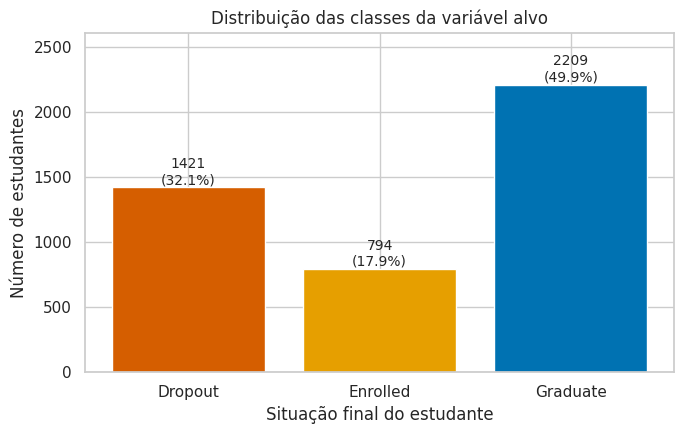

Razão de desequilíbrio (classe majoritária / classe minoritária): 2.78


In [17]:
contagem_alvo = df[TARGET].value_counts().reindex(CLASS_ORDER)
proporcao_alvo = (contagem_alvo / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(contagem_alvo.index, contagem_alvo.values,
                color=[CLASS_COLORS[c] for c in contagem_alvo.index])
for barra, pct in zip(barras, proporcao_alvo.values):
    ax.annotate(f"{int(barra.get_height())}\n({pct}%)",
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Distribuição das classes da variável alvo")
ax.set_xlabel("Situação final do estudante")
ax.set_ylabel("Número de estudantes")
ax.set_ylim(0, contagem_alvo.max() * 1.18)
plt.tight_layout()
plt.show()

print(f"Razão de desequilíbrio (classe majoritária / classe minoritária): "
      f"{contagem_alvo.max() / contagem_alvo.min():.2f}")

A distribuição mostra desequilíbrio moderado entre as classes. Metade dos estudantes (2209, ou 49,9%) concluiu o curso, quase um terço (1421, ou 32,1%) evadiu e 794 (17,9%) permaneciam matriculados ao final do prazo regular. A razão entre a classe majoritária e a minoritária é de 2,78 para 1. Para as perguntas do trabalho, esse resultado fixa as proporções de referência contra as quais os grupos são comparados nas seções seguintes. Uma taxa de evasão de 32,1% é o valor esperado em um grupo sem associação com a situação final. O cuidado pertinente é que a classe **Enrolled** é a menor, de modo que as proporções dessa classe em subgrupos pequenos são as mais instáveis. Esta etapa não aplica balanceamento de classes, pois a reamostragem só faz sentido sobre a partição de treinamento, dentro do processo de validação de um modelo (ver seção 4.7).

### 3.2.2 Distribuição dos atributos numéricos

Os histogramas a seguir mostram a distribuição de cada atributo numérico. A finalidade é identificar assimetrias, multimodalidades e escalas que possam exigir transformação.

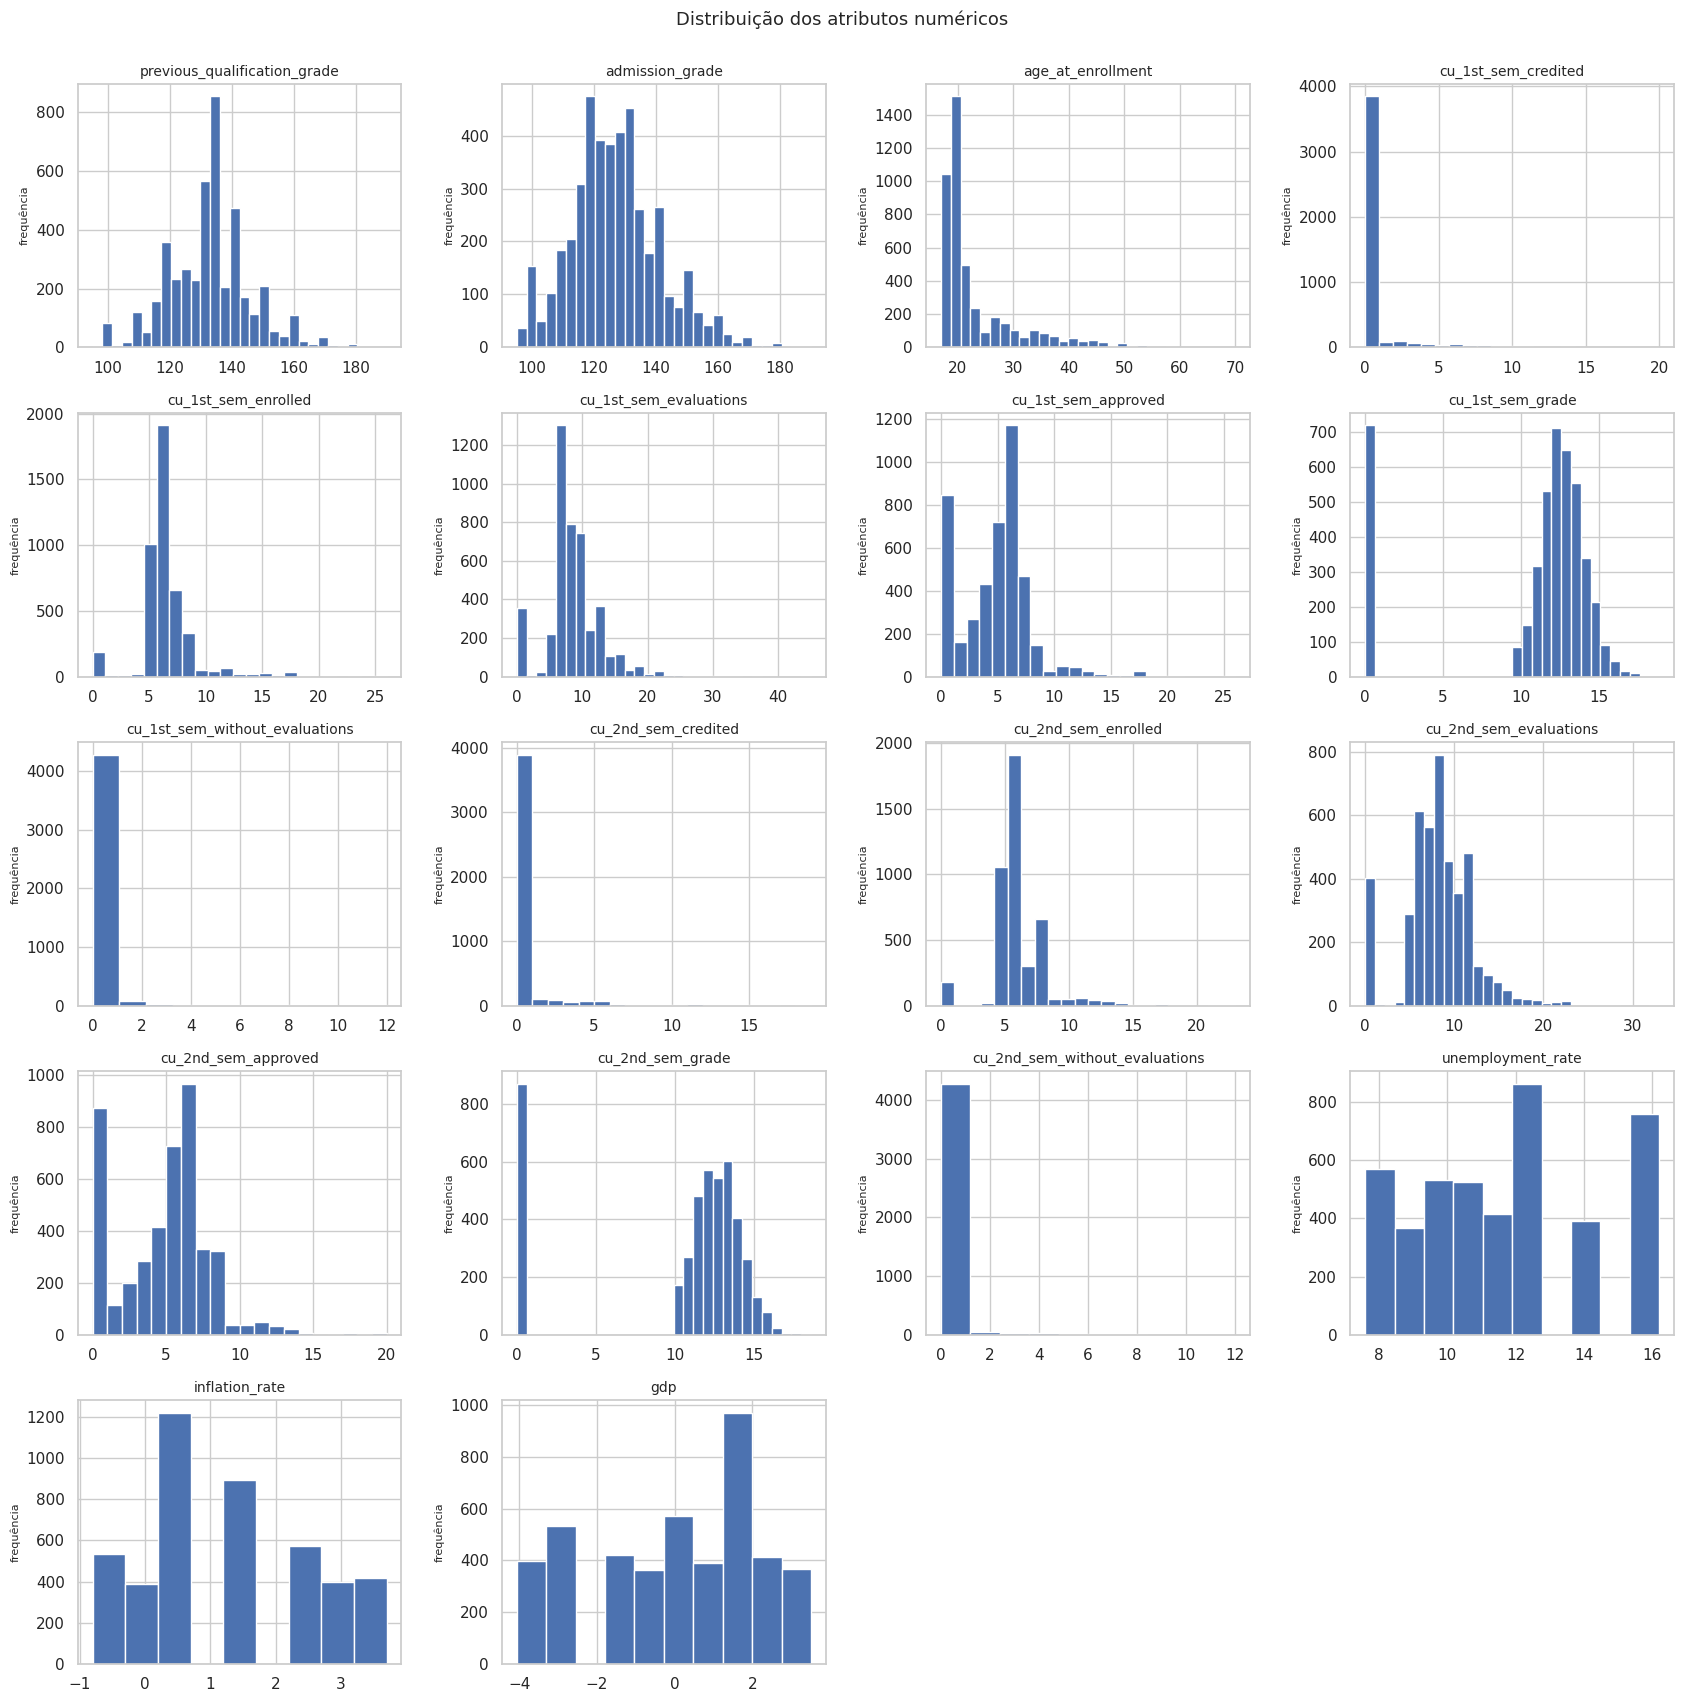

In [18]:
n_cols = 4
n_rows = int(np.ceil(len(ATRIBUTOS_NUMERICOS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 3.4 * n_rows))
for ax, col in zip(axes.flat, ATRIBUTOS_NUMERICOS):
    n_bins = min(30, df[col].nunique())
    ax.hist(df[col], bins=n_bins, color="#4C72B0", edgecolor="white")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("frequência", fontsize=8)
for ax in axes.flat[len(ATRIBUTOS_NUMERICOS):]:
    ax.set_visible(False)
fig.suptitle("Distribuição dos atributos numéricos", y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

Os histogramas revelam três famílias de distribuições. As notas de qualificação anterior e de admissão têm forma aproximadamente simétrica e unimodal, próxima da normal, e são bons candidatos à padronização. A idade de ingresso apresenta forte assimetria à direita, com a maioria dos estudantes entre 18 e 22 anos e uma cauda longa até 70 anos, o que recomenda cautela com medidas sensíveis a valores extremos, como a média. As notas semestrais são claramente bimodais, com uma massa de valores em zero e outra concentrada entre 10 e 15 pontos, confirmando a dupla natureza do zero discutida anteriormente.

Os atributos de contagem de unidades curriculares (creditadas, sem avaliação) estão fortemente concentrados em zero, com cauda longa. Os atributos de inscrição e aprovação têm picos em torno de 5 a 7 unidades, mas com valores extremos acima de 20 no caso das inscrições e avaliações, que serão examinados nos diagramas de caixa. Os indicadores macroeconômicos têm distribuições discretas com poucos valores, pois dependem apenas do ano de ingresso. Em conjunto, os histogramas indicam que a diversidade de escalas (0 a 20, 0 a 200, 17 a 70, percentuais negativos e positivos) exige normalização ou padronização para algoritmos baseados em distância ou gradiente.

### 3.2.3 Valores discrepantes nos atributos numéricos

Os diagramas de caixa permitem identificar valores discrepantes segundo o critério do intervalo interquartil.

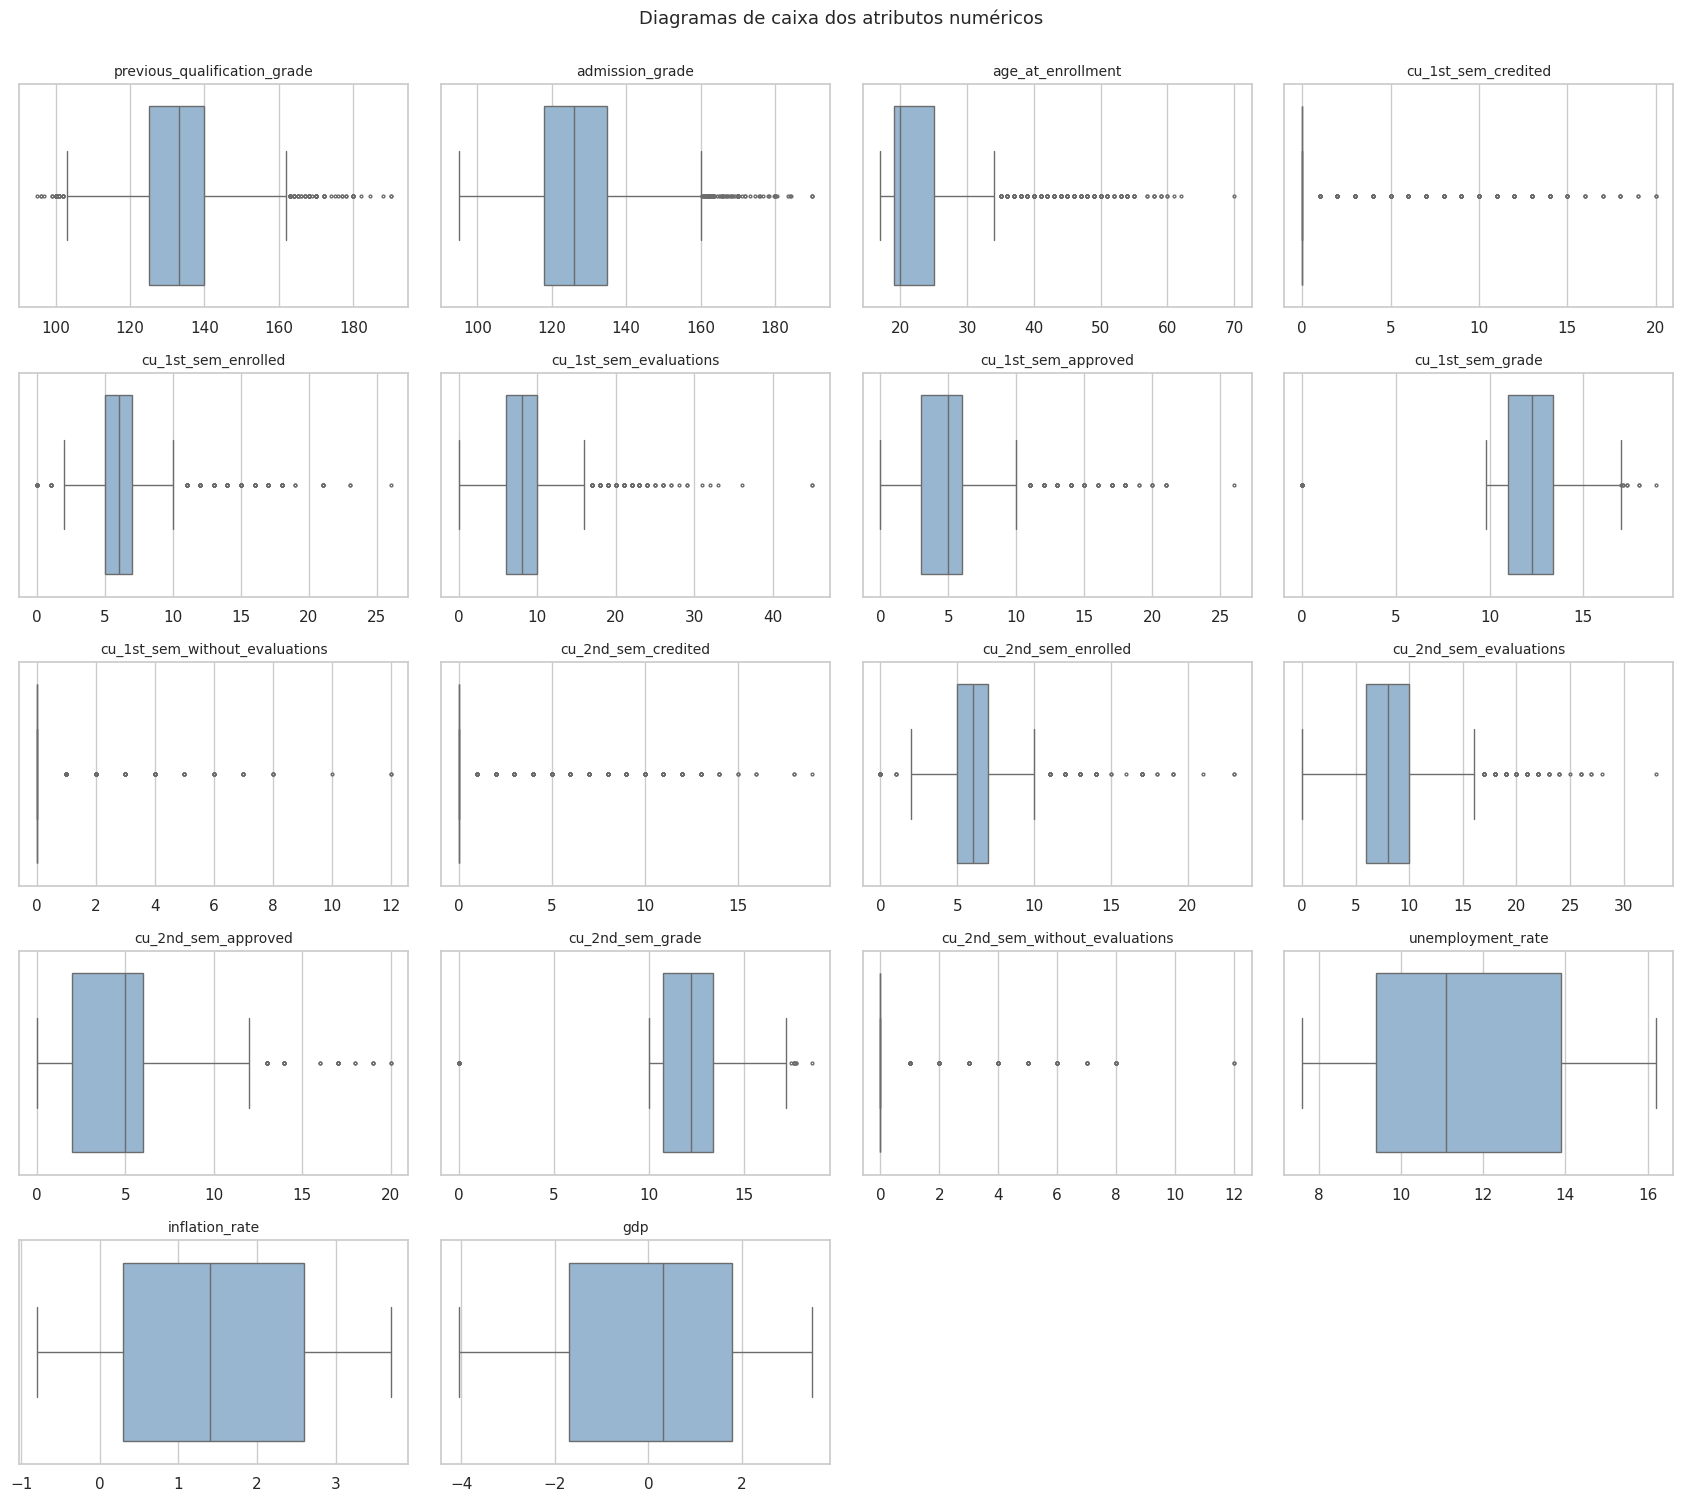

In [19]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 3.0 * n_rows))
for ax, col in zip(axes.flat, ATRIBUTOS_NUMERICOS):
    sns.boxplot(x=df[col], ax=ax, color="#8FB7D9", fliersize=2)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
for ax in axes.flat[len(ATRIBUTOS_NUMERICOS):]:
    ax.set_visible(False)
fig.suptitle("Diagramas de caixa dos atributos numéricos", y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

In [20]:
def marcar_outliers_iqr(serie):
    """Marca os valores fora do intervalo [Q1 - 1,5 IQR, Q3 + 1,5 IQR]."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)


mascaras_outliers = pd.DataFrame({c: marcar_outliers_iqr(df[c]) for c in ATRIBUTOS_NUMERICOS})
outliers = pd.DataFrame({"outliers_iqr": mascaras_outliers.sum()})
outliers["percentual"] = (outliers["outliers_iqr"] / len(df) * 100).round(1)
outliers.sort_values("outliers_iqr", ascending=False)

,outliers_iqr,percentual
cu_2nd_sem_grade,877,19.8
cu_1st_sem_grade,726,16.4
cu_1st_sem_credited,577,13.0
cu_2nd_sem_credited,530,12.0
age_at_enrollment,441,10.0
cu_1st_sem_enrolled,424,9.6
cu_2nd_sem_enrolled,369,8.3
cu_1st_sem_without_evaluations,294,6.6
cu_2nd_sem_without_evaluations,282,6.4
cu_1st_sem_approved,180,4.1


In [21]:
# Valores extremos de carga semestral: registros com mais de 20 unidades inscritas em algum semestre
LIMITE_CARGA = 20
carga_extrema = (df["cu_1st_sem_enrolled"] > LIMITE_CARGA) | (df["cu_2nd_sem_enrolled"] > LIMITE_CARGA)
df.loc[carga_extrema, ["cu_1st_sem_enrolled", "cu_1st_sem_credited", "cu_1st_sem_approved",
                       "cu_2nd_sem_enrolled", "cu_2nd_sem_credited", "cu_2nd_sem_approved",
                       "age_at_enrollment", TARGET]]

,cu_1st_sem_enrolled,cu_1st_sem_credited,cu_1st_sem_approved,cu_2nd_sem_enrolled,cu_2nd_sem_credited,cu_2nd_sem_approved,age_at_enrollment,target
180,21,19,21,19,13,19,35,Graduate
2256,21,18,21,16,12,12,25,Dropout
2476,23,18,20,23,18,20,28,Graduate
2502,21,14,20,14,10,14,26,Graduate
2863,21,20,21,19,19,19,41,Graduate
3093,23,18,20,23,18,20,22,Graduate
3635,21,12,18,21,12,18,21,Graduate
3961,26,20,26,17,14,17,23,Graduate
4313,21,19,21,19,13,19,37,Graduate


In [22]:
# D2: efeito de remover toda linha com pelo menos um valor discrepante pelo critério IQR
linha_com_outlier = mascaras_outliers.any(axis=1)
df_sem_outliers = df.loc[~linha_com_outlier]

comparacao_outliers = pd.DataFrame({
    "manter_n": df[TARGET].value_counts(),
    "manter_%": (df[TARGET].value_counts(normalize=True) * 100).round(1),
    "remover_n": df_sem_outliers[TARGET].value_counts(),
    "remover_%": (df_sem_outliers[TARGET].value_counts(normalize=True) * 100).round(1),
}).reindex(CLASS_ORDER)
comparacao_outliers["perda_da_classe_%"] = (100 - comparacao_outliers["remover_n"] / comparacao_outliers["manter_n"] * 100).round(1)

print(f"Linhas com pelo menos um valor discrepante: {linha_com_outlier.sum()} de {len(df)} "
      f"({linha_com_outlier.mean() * 100:.1f}%)")
print(f"Idade máxima após a remoção: {df_sem_outliers['age_at_enrollment'].max()} anos "
      f"(antes: {df['age_at_enrollment'].max()} anos)")
comparacao_outliers

Linhas com pelo menos um valor discrepante: 2020 de 4424 (45.7%)
Idade máxima após a remoção: 34 anos (antes: 70 anos)


,manter_n,manter_%,remover_n,remover_%,perda_da_classe_%
target,,,,,
Dropout,1421,32.1,372,15.5,73.8
Enrolled,794,17.9,461,19.2,41.9
Graduate,2209,49.9,1571,65.3,28.9


Segundo o critério do intervalo interquartil, vários atributos apresentam proporção elevada de valores "discrepantes", chegando a 19,8% na nota do segundo semestre. O critério pressupõe distribuições razoavelmente simétricas, o que não ocorre aqui. Nas notas semestrais, os valores sinalizados são os zeros já discutidos. Nos atributos concentrados em zero, como unidades creditadas e unidades sem avaliação, qualquer valor positivo é sinalizado. Na idade de ingresso, são marcados os 441 estudantes mais velhos, que constituem um segmento real da população.

**Valores extremos e erros de registro.** Os valores que poderiam indicar erro são as cargas acima de 20 unidades inscritas em um semestre, implausíveis para um semestre regular. A tabela mostra que são apenas 9 registros e que todos têm entre 12 e 20 unidades creditadas no mesmo semestre. São estudantes com aproveitamento de estudos anteriores, cujas inscrições incluem as unidades creditadas. Os valores são extremos, mas coerentes entre si, e não há indício de erro de registro. As verificações da seção 3.1.3 também não encontraram valores fora dos intervalos documentados. O único problema de registro identificado na base é a lacuna das unidades curriculares do curso 171.

**Decisão D2, manter os valores discrepantes.** A comparação acima mede o efeito das duas alternativas. Remover toda linha com algum valor discrepante eliminaria 2020 das 4424 linhas (45,7%) e de forma muito desigual. Seriam perdidos 73,8% dos evadidos, contra 28,9% dos concluintes, e a proporção de evasão na base cairia de 32,1% para 15,5%. A idade máxima passaria de 70 para 34 anos, o que excluiria justamente o segmento examinado em H3. A remoção distorceria as respostas às perguntas do trabalho, e por isso os valores são mantidos. O limite da decisão é que atributos de cauda longa continuam sensíveis a medidas como a média e a transformações de escala, o que é considerado na decisão D4.

### 3.2.4 Atributos de desempenho acadêmico por classe

A primeira hipótese do projeto afirma que o desempenho nos dois primeiros semestres reúne os atributos mais associados à situação final. Os diagramas de caixa por classe e a tabela de medianas permitem avaliá-la.

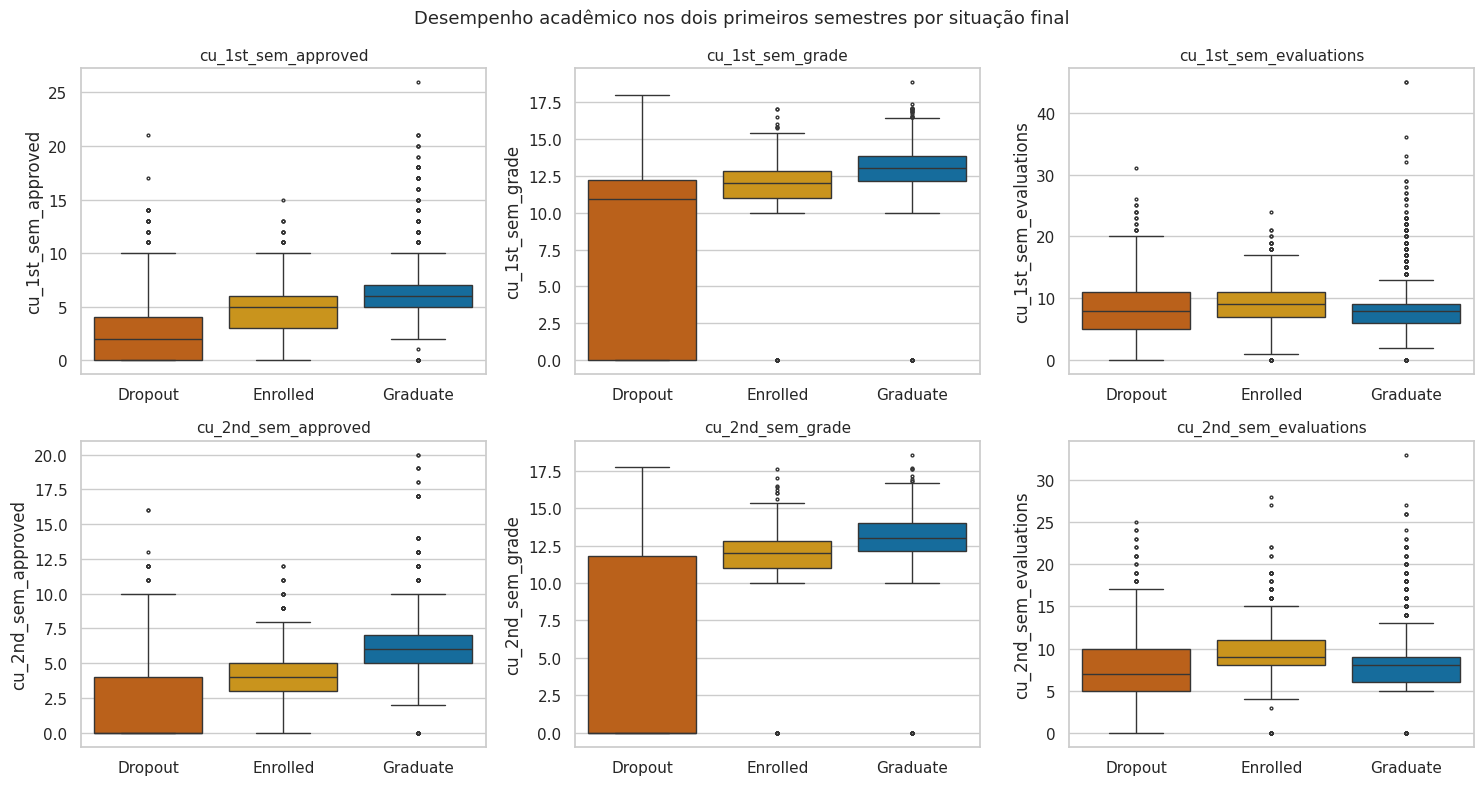

In [23]:
atributos_desempenho = [
    "cu_1st_sem_approved", "cu_1st_sem_grade", "cu_1st_sem_evaluations",
    "cu_2nd_sem_approved", "cu_2nd_sem_grade", "cu_2nd_sem_evaluations",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, atributos_desempenho):
    sns.boxplot(data=df, x=TARGET, y=col, order=CLASS_ORDER, hue=TARGET, hue_order=CLASS_ORDER,
                palette=CLASS_COLORS, legend=False, ax=ax, fliersize=2)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
fig.suptitle("Desempenho acadêmico nos dois primeiros semestres por situação final", fontsize=13)
plt.tight_layout()
plt.show()

In [24]:
# Medianas dos atributos de desempenho por situação final, como apoio numérico à figura
df.groupby(TARGET)[atributos_desempenho].median().reindex(CLASS_ORDER).round(2)

,cu_1st_sem_approved,cu_1st_sem_grade,cu_1st_sem_evaluations,cu_2nd_sem_approved,cu_2nd_sem_grade,cu_2nd_sem_evaluations
target,,,,,,
Dropout,2.0,10.93,8.0,0.0,0.0,7.0
Enrolled,5.0,12.00,9.0,4.0,12.0,9.0
Graduate,6.0,13.00,8.0,6.0,13.0,8.0


Os dados são compatíveis com H1. Os estudantes que concluíram o curso apresentam mediana de 6 aprovações em cada semestre, enquanto os evadidos têm mediana de 2 aprovações no primeiro semestre e de zero no segundo. Os estudantes ainda matriculados ocupam posição intermediária, com medianas de 5 e 4 aprovações. O padrão se repete nas notas. As medianas dos concluintes e dos matriculados ficam em 13 e 12 pontos nos dois semestres. A mediana dos evadidos é de 10,93 no primeiro semestre e cai a zero no segundo, o que indica que mais da metade dos evadidos não obteve nota positiva no segundo semestre. O número de avaliações realizadas, por sua vez, pouco difere entre as classes (medianas entre 7 e 9).

A separação entre evadidos e concluintes é mais nítida no segundo semestre do que no primeiro, o que sugere que o afastamento se consolida ao longo do primeiro ano. As caixas da classe **Enrolled** se sobrepõem às das outras duas classes em todos os painéis, evidência indireta em favor de H4. Dois cuidados limitam a leitura. As notas dos evadidos incluem os zeros de ausência de avaliação discutidos na seção 3.1.3, de modo que parte da diferença reflete não participação, e não desempenho avaliado. Além disso, a comparação é univariada e descritiva, e não estabelece que o baixo desempenho cause a evasão.

### 3.2.5 Fatores financeiros e demográficos por classe

A segunda e a terceira hipóteses referem-se a fatores financeiros e demográficos. Os gráficos de barras empilhadas mostram a proporção de cada classe dentro de cada categoria dos atributos binários, e a tabela seguinte traz os mesmos percentuais em números.

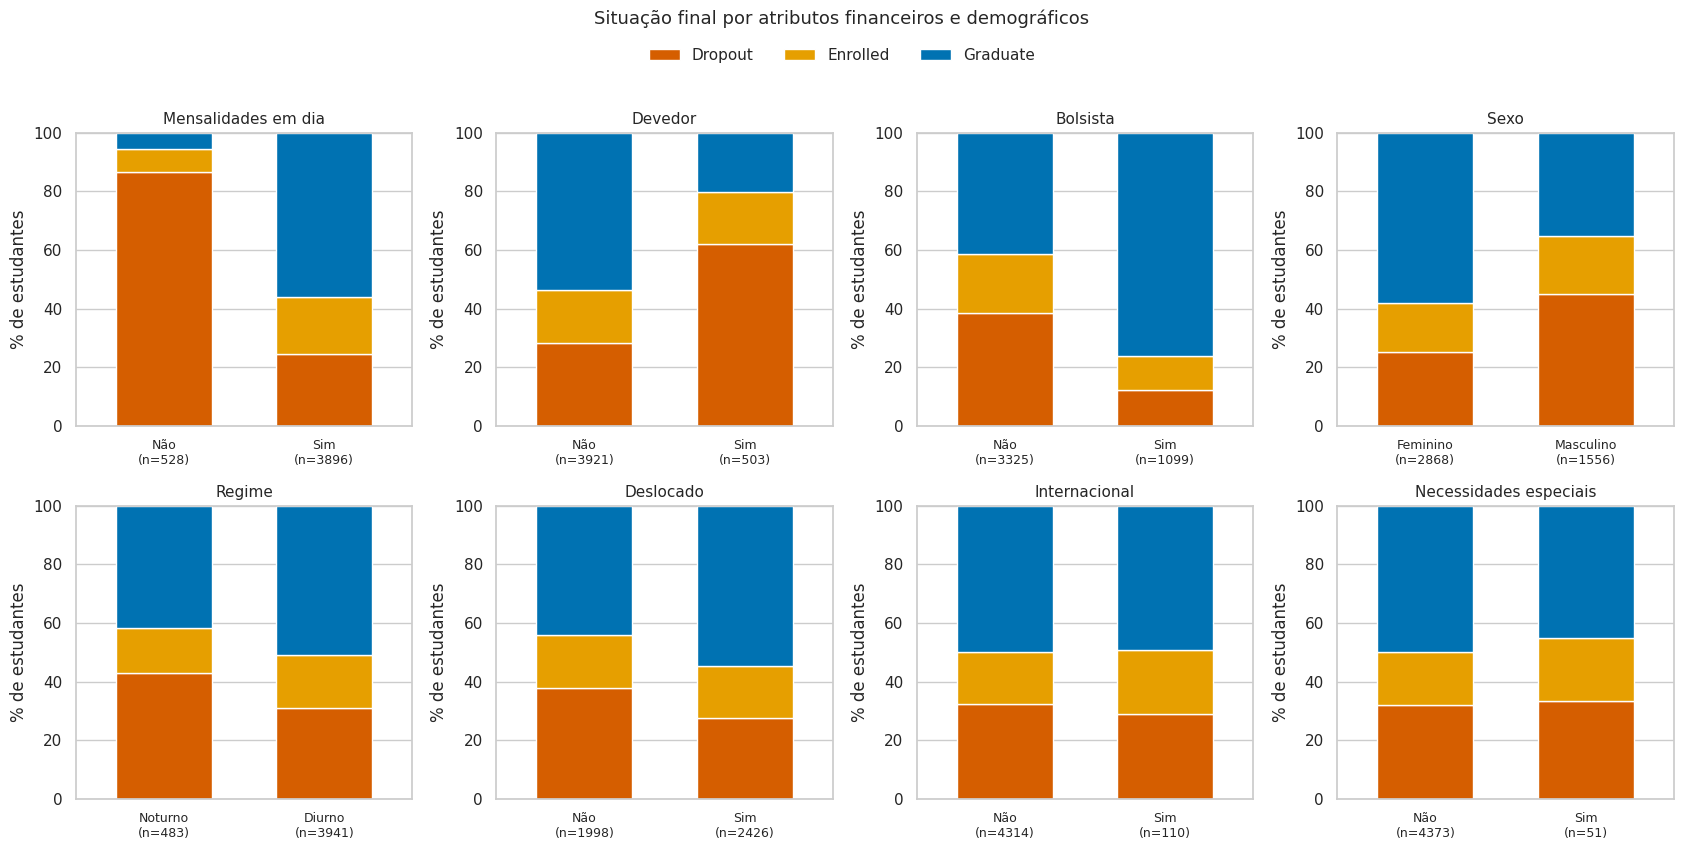

In [25]:
rotulos_binarios = {
    "tuition_fees_up_to_date": ("Mensalidades em dia", {0: "Não", 1: "Sim"}),
    "debtor": ("Devedor", {0: "Não", 1: "Sim"}),
    "scholarship_holder": ("Bolsista", {0: "Não", 1: "Sim"}),
    "gender": ("Sexo", {0: "Feminino", 1: "Masculino"}),
    "daytime_evening_attendance": ("Regime", {0: "Noturno", 1: "Diurno"}),
    "displaced": ("Deslocado", {0: "Não", 1: "Sim"}),
    "international": ("Internacional", {0: "Não", 1: "Sim"}),
    "educational_special_needs": ("Necessidades especiais", {0: "Não", 1: "Sim"}),
}

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, (col, (titulo, mapa)) in zip(axes.flat, rotulos_binarios.items()):
    tabela = pd.crosstab(df[col], df[TARGET], normalize="index")[CLASS_ORDER] * 100
    tabela.index = tabela.index.map(mapa)
    tabela.plot(kind="bar", stacked=True, ax=ax, color=[CLASS_COLORS[c] for c in CLASS_ORDER],
                legend=False, rot=0, width=0.6)
    n_por_cat = df[col].value_counts().sort_index()
    ax.set_xticklabels([f"{mapa[i]}\n(n={n_por_cat[i]})" for i in n_por_cat.index], fontsize=9)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("% de estudantes")
    ax.set_ylim(0, 100)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03), frameon=False)
fig.suptitle("Situação final por atributos financeiros e demográficos", y=1.06, fontsize=13)
plt.tight_layout()
plt.show()

In [26]:
def situacao_por_categoria(df, coluna, rotulos=None):
    """Percentual de cada situação final dentro de cada categoria de um atributo, com o tamanho do grupo."""
    tabela = (pd.crosstab(df[coluna], df[TARGET], normalize="index")[CLASS_ORDER] * 100).round(1)
    tabela["n"] = df[coluna].value_counts().reindex(tabela.index)
    if rotulos is not None:
        tabela.index = tabela.index.map(rotulos)
    return tabela


pd.concat({titulo: situacao_por_categoria(df, col, mapa) for col, (titulo, mapa) in rotulos_binarios.items()},
          names=["atributo", "categoria"])

target                            Dropout  Enrolled  Graduate     n
atributo               categoria                                   
Mensalidades em dia    Não           86.6       8.0       5.5   528
                       Sim           24.7      19.3      56.0  3896
Devedor                Não           28.3      18.0      53.8  3921
                       Sim           62.0      17.9      20.1   503
Bolsista               Não           38.7      20.0      41.3  3325
                       Sim           12.2      11.8      76.0  1099
Sexo                   Feminino      25.1      17.0      57.9  2868
                       Masculino     45.1      19.7      35.2  1556
Regime                 Noturno       42.9      15.5      41.6   483
                       Diurno        30.8      18.2      51.0  3941
Deslocado              Não           37.6      18.1      44.3  1998
                       Sim           27.6      17.8      54.6  2426
Internacional          Não           32.2      17.8      50.0  4314
                       Sim           29.1      21.8      49.1   110
Necessidades especiais Não           32.1      17.9      50.0  4373
                       Sim           33.3      21.6      45.1    51

Os fatores financeiros exibem as associações mais intensas entre os atributos binários, em linha com H2. Entre os 528 estudantes com mensalidades em atraso, 86,6% evadiram, contra 24,7% entre os 3896 que estão em dia. Entre os 503 devedores, 62,0% evadiram, contra 28,3% entre os não devedores. Os 1099 bolsistas apresentam taxa de conclusão de 76,0%, bem acima dos 41,3% dos não bolsistas, e taxa de evasão de 12,2%, contra 38,7%.

O cuidado principal é a direção da associação. A regularidade das mensalidades e a condição de devedor podem ser, em parte, consequências do processo de evasão e não antecedentes dele, pois um estudante que decide abandonar o curso deixa de pagar. A base não informa em que momento esses atributos foram medidos. A bolsa, por sua vez, costuma ser concedida por critérios que também se relacionam ao desempenho. Os percentuais descrevem associações e não permitem afirmar que a situação financeira cause a evasão.

Nos atributos demográficos, ligados a H3, o sexo mostra a maior diferença. Os estudantes do sexo masculino evadem em 45,1% dos casos, contra 25,1% das estudantes, e concluem em 35,2%, contra 57,9%. O regime noturno está associado a maior evasão (42,9%, contra 30,8% no diurno), assim como a condição de não deslocado (37,6%, contra 27,6%). Os atributos `international` e `educational_special_needs` não mostram diferença relevante (29,1% e 33,3% de evasão nos grupos minoritários, contra 32,2% e 32,1%), e seus grupos minoritários têm apenas 110 e 51 estudantes, o que torna essas proporções pouco precisas.

### 3.2.6 Idade de ingresso por classe

A terceira hipótese prevê maior proporção de evasão entre estudantes que ingressam mais velhos.

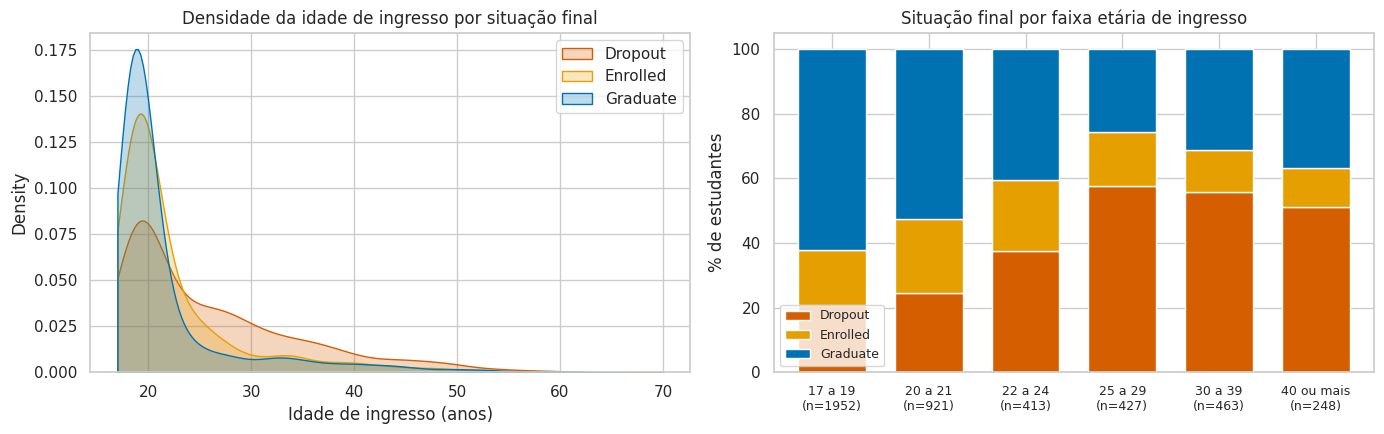

In [27]:
# Faixas etárias de ingresso usadas apenas para descrição
FAIXAS_IDADE = [16, 19, 21, 24, 29, 39, 100]
ROTULOS_IDADE = ["17 a 19", "20 a 21", "22 a 24", "25 a 29", "30 a 39", "40 ou mais"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for classe in CLASS_ORDER:
    sns.kdeplot(df.loc[df[TARGET] == classe, "age_at_enrollment"], ax=axes[0],
                label=classe, color=CLASS_COLORS[classe], fill=True, alpha=0.25, clip=(17, 70))
axes[0].set_title("Densidade da idade de ingresso por situação final")
axes[0].set_xlabel("Idade de ingresso (anos)")
axes[0].legend()

faixas = pd.cut(df["age_at_enrollment"], bins=FAIXAS_IDADE, labels=ROTULOS_IDADE)
tabela = pd.crosstab(faixas, df[TARGET], normalize="index")[CLASS_ORDER] * 100
tabela.plot(kind="bar", stacked=True, ax=axes[1], color=[CLASS_COLORS[c] for c in CLASS_ORDER], rot=0, width=0.7)
contagens = faixas.value_counts().reindex(tabela.index)
axes[1].set_xticklabels([f"{f}\n(n={n})" for f, n in contagens.items()], fontsize=9)
axes[1].set_title("Situação final por faixa etária de ingresso")
axes[1].set_xlabel("")
axes[1].set_ylabel("% de estudantes")
axes[1].legend(title="", loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

In [28]:
# Percentuais da figura acima, com o tamanho de cada faixa etária
tabela.round(1).assign(n=contagens.values)

target,Dropout,Enrolled,Graduate,n
age_at_enrollment,,,,
17 a 19,21.0,17.0,62.1,1952
20 a 21,24.5,22.8,52.7,921
22 a 24,37.5,22.0,40.4,413
25 a 29,57.6,16.9,25.5,427
30 a 39,55.7,13.0,31.3,463
40 ou mais,51.2,12.1,36.7,248


A proporção de evasão cresce com a idade de ingresso, em linha com H3. Entre os 1952 estudantes que ingressam com 17 a 19 anos, 21,0% evadem e 62,1% concluem. A evasão sobe para 24,5% na faixa de 20 a 21 anos e para 37,5% na de 22 a 24, atinge o máximo de 57,6% na faixa de 25 a 29 anos e permanece acima de 50% nas faixas seguintes (55,7% entre 30 e 39 anos e 51,2% a partir de 40), nas quais a evasão é a situação mais frequente. A curva de densidade dos evadidos é visivelmente mais deslocada para a direita do que a dos concluintes.

A relação não é linear. Ela cresce em degraus até os 25 a 29 anos e depois se estabiliza, com leve recuo. As faixas acima de 25 anos têm entre 248 e 463 estudantes, tamanho suficiente para sustentar a comparação, embora com menor precisão do que as faixas mais jovens. O cuidado de interpretação é que a idade se confunde com a via de ingresso e com o regime noturno, examinados a seguir, de modo que o gráfico não isola o efeito da idade. As faixas etárias são usadas aqui apenas para descrever os dados e não são incorporadas ao conjunto processado (ver seção 4.7).

### 3.2.7 Curso e via de ingresso

Entre os atributos nominais de alta cardinalidade, o curso e a via de ingresso são os mais interpretáveis. O gráfico a seguir mostra a taxa de evasão por curso, com os nomes recuperados da documentação original.

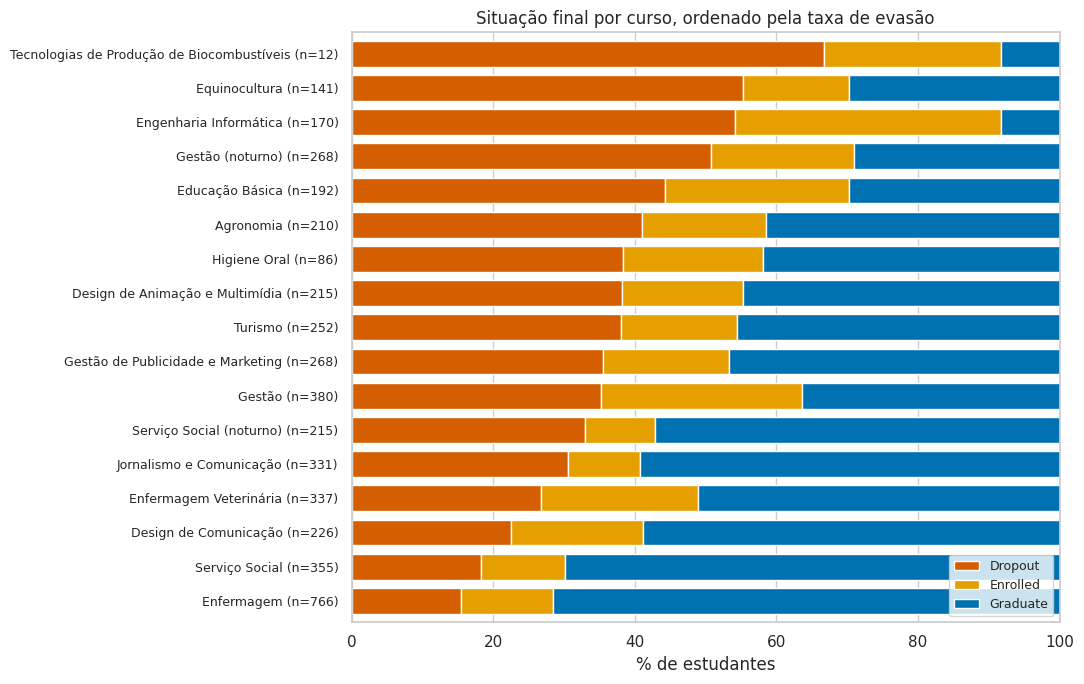

In [29]:
NOMES_CURSOS = {
    33: "Tecnologias de Produção de Biocombustíveis", 171: "Design de Animação e Multimídia",
    8014: "Serviço Social (noturno)", 9003: "Agronomia", 9070: "Design de Comunicação",
    9085: "Enfermagem Veterinária", 9119: "Engenharia Informática", 9130: "Equinocultura",
    9147: "Gestão", 9238: "Serviço Social", 9254: "Turismo", 9500: "Enfermagem",
    9556: "Higiene Oral", 9670: "Gestão de Publicidade e Marketing",
    9773: "Jornalismo e Comunicação", 9853: "Educação Básica", 9991: "Gestão (noturno)",
}

tabela_curso = pd.crosstab(df["course"].map(NOMES_CURSOS), df[TARGET], normalize="index")[CLASS_ORDER] * 100
tabela_curso = tabela_curso.sort_values("Dropout", ascending=True)
n_curso = df["course"].map(NOMES_CURSOS).value_counts()

fig, ax = plt.subplots(figsize=(11, 7))
tabela_curso.plot(kind="barh", stacked=True, ax=ax, color=[CLASS_COLORS[c] for c in CLASS_ORDER], width=0.75)
ax.set_yticklabels([f"{c} (n={n_curso[c]})" for c in tabela_curso.index], fontsize=9)
ax.set_title("Situação final por curso, ordenado pela taxa de evasão")
ax.set_xlabel("% de estudantes")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

A taxa de evasão varia enormemente entre cursos, de cerca de 15% em Enfermagem a 67% em Tecnologias de Produção de Biocombustíveis. Enfermagem, Serviço Social e Design de Comunicação apresentam as menores taxas de evasão e as maiores de conclusão. No extremo oposto, Equinocultura, Engenharia Informática e Gestão no regime noturno superam 50% de evasão. O caso de Engenharia Informática é notável, pois apenas 14 dos 170 estudantes concluíram no prazo regular, com uma parcela expressiva ainda matriculada, o que sugere um curso em que o atraso é a norma. O curso é, portanto, um atributo com forte poder discriminativo, e sua codificação adequada (one-hot, dado o caráter nominal) é essencial.

Há um ponto de atenção quanto ao tamanho das turmas. O curso de Biocombustíveis tem apenas 12 estudantes, e Equinocultura e Engenharia Informática têm menos de 200. As proporções em cursos pequenos são instáveis, e um modelo pode sobreajustar a essas categorias. Essa observação reforça a conveniência de agrupar categorias raras, estratégia que será aplicada aos nominais de alta cardinalidade.

In [30]:
tabela_modo = pd.crosstab(df["application_mode"], df[TARGET])
tabela_modo["n"] = tabela_modo.sum(axis=1)
tabela_modo["taxa_evasao_%"] = (tabela_modo["Dropout"] / tabela_modo["n"] * 100).round(1)
tabela_modo = tabela_modo[tabela_modo["n"] >= 30].sort_values("taxa_evasao_%", ascending=False)

NOMES_MODOS = {
    1: "1ª fase, contingente geral", 17: "2ª fase, contingente geral", 18: "3ª fase, contingente geral",
    39: "Maiores de 23 anos", 42: "Transferência", 43: "Mudança de curso", 44: "Diploma de especialização tecnológica",
    51: "Mudança de instituição/curso", 53: "Diploma de ciclo curto", 7: "Titulares de outro curso superior",
    15: "Estudante internacional", 16: "1ª fase, contingente especial (Madeira)", 5: "1ª fase, contingente especial (Açores)",
    10: "Portaria 854-B/99", 2: "Portaria 612/93", 26: "Portaria 533-A/99 (plano diferente)",
    27: "Portaria 533-A/99 (outra instituição)", 57: "Mudança de instituição/curso (internacional)",
}
tabela_modo.index = [f"{NOMES_MODOS.get(i, i)} ({i})" for i in tabela_modo.index]
tabela_modo[["n", "Dropout", "Enrolled", "Graduate", "taxa_evasao_%"]]

target,n,Dropout,Enrolled,Graduate,taxa_evasao_%
Titulares de outro curso superior (7),139,85,7,47,61.2
Maiores de 23 anos (39),785,435,121,229,55.4
Transferência (42),77,34,11,32,44.2
Mudança de curso (43),312,115,75,122,36.9
"3ª fase, contingente geral (18)",124,45,16,63,36.3
Mudança de instituição/curso (51),59,20,13,26,33.9
Diploma de especialização tecnológica (44),213,63,56,94,29.6
"2ª fase, contingente geral (17)",872,256,159,457,29.4
"1ª fase, contingente geral (1)",1708,345,300,1063,20.2
Estudante internacional (15),30,5,10,15,16.7


A tabela das vias de ingresso com pelo menos 30 estudantes mostra que os titulares de outro curso superior (61%) e o contingente de maiores de 23 anos (55%) apresentam as maiores taxas de evasão, enquanto os ingressantes pela primeira fase do concurso geral, que são a maioria, evadem em cerca de 20% dos casos. Os ingressantes por transferência ou mudança de curso também apresentam taxas elevadas. Esse resultado é coerente com o achado sobre a idade, uma vez que a via de maiores de 23 anos é, por definição, composta por estudantes mais velhos. Há, portanto, redundância parcial entre `application_mode` e `age_at_enrollment`, o que não constitui problema para a maioria dos algoritmos, mas pode ser considerado em uma futura seleção de atributos.

### 3.2.8 Correlação entre os atributos numéricos

A matriz de correlação de Spearman, mais adequada do que a de Pearson para distribuições assimétricas e relações monotônicas não lineares, identifica redundâncias entre atributos.

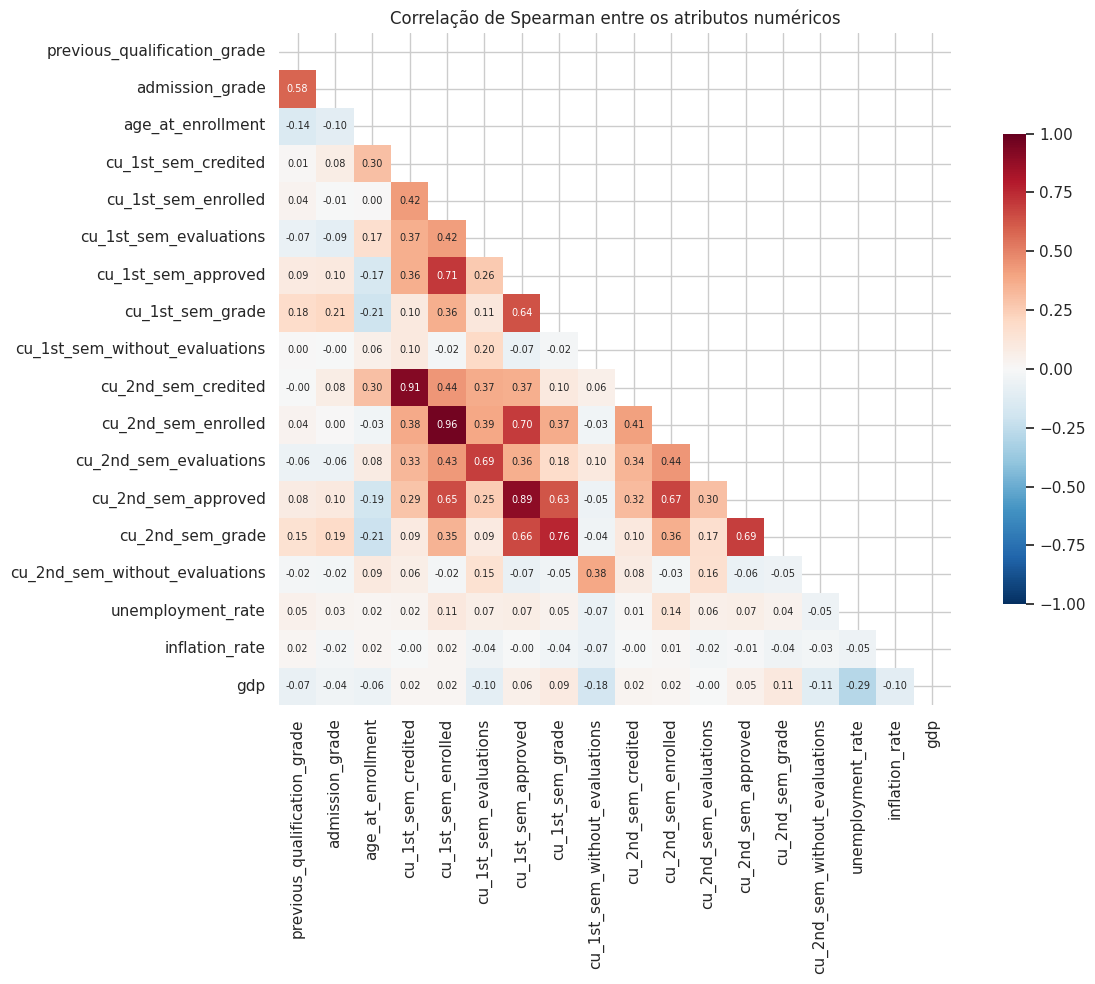

In [31]:
corr = df[ATRIBUTOS_NUMERICOS].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mascara, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlação de Spearman entre os atributos numéricos")
plt.tight_layout()
plt.show()

In [32]:
# Pares de atributos com correlação absoluta elevada
pares = corr.where(~mascara).stack().reset_index()
pares.columns = ["atributo_1", "atributo_2", "correlação"]
pares["abs"] = pares["correlação"].abs()
pares[pares["abs"] >= 0.7].sort_values("abs", ascending=False).drop(columns="abs").round(3)

,atributo_1,atributo_2,correlação
49,cu_2nd_sem_enrolled,cu_1st_sem_enrolled,0.962
39,cu_2nd_sem_credited,cu_1st_sem_credited,0.914
72,cu_2nd_sem_approved,cu_1st_sem_approved,0.892
85,cu_2nd_sem_grade,cu_1st_sem_grade,0.762
19,cu_1st_sem_approved,cu_1st_sem_enrolled,0.707


A matriz revela um bloco de atributos de desempenho fortemente correlacionados entre si. Os atributos homólogos do primeiro e do segundo semestres apresentam correlação muito elevada, com destaque para as unidades inscritas (0,96), as unidades creditadas (0,91) e as aprovações (0,89), e as notas dos dois semestres correlacionam-se acima de 0,75. No primeiro semestre, aprovações e inscrições correlacionam-se em 0,71. No segundo, o par correspondente fica abaixo do limiar de 0,7 adotado na tabela. As unidades creditadas dos dois semestres refletem a mesma condição de aproveitamento de estudos anteriores, o que explica sua quase redundância. A nota de admissão e a nota da qualificação anterior correlacionam-se moderadamente, como se observa no mapa de calor.

Essa redundância tem duas consequências para o projeto. Para algoritmos lineares, a multicolinearidade pode instabilizar os coeficientes, o que sugere a eventual remoção de um atributo de cada par altamente redundante ou o uso de regularização. Para algoritmos baseados em árvores, a redundância não prejudica o desempenho, mas dilui as medidas de importância entre atributos equivalentes. Nesta etapa, optou-se por preservar todos os atributos nas visões processadas e registrar a redundância como insumo para a seleção de atributos na etapa de modelagem. A matriz também mostra que os indicadores macroeconômicos são praticamente independentes dos atributos individuais, o que é coerente com sua natureza contextual.

# 4. Pré-processamento de dados

A análise exploratória fundamenta as operações de pré-processamento, apresentadas passo a passo. A sequência segue uma ordem deliberada. Primeiro são realizadas operações que não aprendem nenhum parâmetro dos dados e que são calculadas linha a linha (tratamento dos valores faltantes implícitos, atributos derivados, tipagem e codificação do alvo). Em seguida, o conjunto é particionado em treinamento e teste. Só então são ajustadas as transformações que aprendem parâmetros dos dados (agrupamento de categorias raras, codificação one-hot e padronização), sempre com a partição de treinamento, para evitar **vazamento de informação** do conjunto de teste.

Os dados de origem são preservados. `df_raw` guarda o arquivo como lido, `df` guarda a mesma base com os nomes padronizados e `df_proc` recebe as transformações. As decisões relevantes estão identificadas como D1 a D4 e resumidas na seção 4.10. A decisão D2, sobre valores discrepantes, foi tomada na seção 3.2.3. Ao final, são salvas duas visões do conjunto processado.

## 4.1 Tratamento dos valores faltantes implícitos e engenharia de atributos

**Decisão D1, problema.** A tabela de zeros por semestre e o perfil dos registros sem inscrição (seção 3.1.3) mostram que a nota zero tem dois significados. Em 349 registros no primeiro semestre e 401 no segundo, ela marca ausência de avaliação, e não desempenho.

**Alternativas.** A alternativa A mantém os dados como estão. A alternativa B trata esses zeros como ausentes, o que exigiria depois excluir as linhas ou imputar um valor. A alternativa C mantém o zero e acrescenta um indicador binário de ausência de avaliações em cada semestre. A célula a seguir compara A e B pelo efeito sobre a nota média de cada classe e pela quantidade de valores que passariam a ausentes.

In [33]:
def comparar_tratamentos_zero(df, sem):
    """Compara a nota média por classe com o zero mantido (A) e com o zero de ausência tratado como ausente (B)."""
    nota = df[f"cu_{sem}_grade"]
    sem_avaliacao = df[f"cu_{sem}_evaluations"] == 0
    nota_b = nota.mask(sem_avaliacao)
    return pd.DataFrame({
        "A_média_com_zeros": nota.groupby(df[TARGET]).mean(),
        "B_média_sem_zeros_de_ausência": nota_b.groupby(df[TARGET]).mean(),
        "B_valores_tornados_ausentes": sem_avaliacao.groupby(df[TARGET]).sum(),
        "B_%_da_classe_afetada": sem_avaliacao.groupby(df[TARGET]).mean() * 100,
    }).reindex(CLASS_ORDER).round(2)


pd.concat({sem: comparar_tratamentos_zero(df, sem) for sem in ("1st_sem", "2nd_sem")}, names=["semestre", TARGET])

A_média_com_zeros  B_média_sem_zeros_de_ausência  B_valores_tornados_ausentes  B_%_da_classe_afetada
semestre target                                                                                                        
1st_sem  Dropout                7.26                           8.78                          246                  17.31
         Enrolled              11.13                          11.53                           28                   3.53
         Graduate              12.64                          13.09                           75                   3.40
2nd_sem  Dropout                5.90                           7.46                          297                  20.90
         Enrolled              11.12                          11.54                           29                   3.65
         Graduate              12.70                          13.14                           75                   3.40

**Efeito das alternativas.** Com o zero mantido (A), a nota média dos evadidos é de 7,26 no primeiro semestre e de 5,90 no segundo. Tratando os zeros de ausência como ausentes (B), essas médias sobem para 8,78 e 7,46, enquanto as dos concluintes mudam pouco (de 12,64 para 13,09 e de 12,70 para 13,14). A alternativa A, portanto, exagera a distância de desempenho entre as classes, pois mistura não participação com nota baixa. A alternativa B corrige a média, mas tornaria ausentes 349 e 401 valores, concentrados nos evadidos (17,3% e 20,9% da classe, contra 3,4% dos concluintes). Excluir essas linhas removeria de forma seletiva os estudantes de maior interesse, e imputar a mediana atribuiria a quem nunca foi avaliado uma nota típica de estudantes regulares.

**Escolha.** Adota-se a alternativa C. O zero é mantido, para não perder linhas nem inventar notas, e os indicadores `no_evaluations_1st_sem` e `no_evaluations_2nd_sem` tornam explícito o segundo significado do zero. A mesma etapa cria atributos derivados de desempenho relativo. A taxa de aprovação (aprovadas sobre inscritas) e a média das notas dos dois semestres resumem o primeiro ano em escala comparável entre estudantes com cargas diferentes, e a variação de aprovações entre semestres descreve a tendência. Quando não há inscrição, a taxa de aprovação recebe zero, e a célula verifica que todos esses casos estão cobertos pelo indicador de ausência de avaliações.

**Verificação e limitação.** A célula abaixo confere que os indicadores somam exatamente 349 e 401 registros e que nenhum registro sem inscrição fica sem indicador. A limitação é que o indicador não distingue a lacuna de registro do curso 171 da ausência real de avaliações nos demais cursos. Essa distinção fica a cargo do atributo `course`. Além disso, `mean_grade_first_year` herda os zeros de ausência e deve ser lida em conjunto com os indicadores.

In [34]:
SEMESTRES = ("1st_sem", "2nd_sem")


def taxa_segura(numerador, denominador):
    """Divide dois vetores retornando zero quando o denominador é zero."""
    return np.where(denominador > 0, numerador / np.where(denominador > 0, denominador, 1), 0.0)


def criar_atributos_derivados(df_in):
    """Acrescenta os indicadores de ausência de avaliação e os atributos de desempenho relativo."""
    df_out = df_in.copy()
    for sem in SEMESTRES:
        # Indicador explícito de ausência de avaliação (zero não informativo na nota)
        df_out[f"no_evaluations_{sem}"] = (df_out[f"cu_{sem}_evaluations"] == 0).astype(int)
        df_out[f"approval_rate_{sem}"] = taxa_segura(df_out[f"cu_{sem}_approved"], df_out[f"cu_{sem}_enrolled"])
    df_out["mean_grade_first_year"] = (df_out["cu_1st_sem_grade"] + df_out["cu_2nd_sem_grade"]) / 2
    df_out["approved_change"] = df_out["cu_2nd_sem_approved"] - df_out["cu_1st_sem_approved"]
    return df_out


df_proc = criar_atributos_derivados(df)

INDICADORES_AUSENCIA = [f"no_evaluations_{sem}" for sem in SEMESTRES]
ATRIBUTOS_DERIVADOS = ["approval_rate_1st_sem", "approval_rate_2nd_sem", "mean_grade_first_year", "approved_change"]
ATRIBUTOS_BINARIOS_PROC = ATRIBUTOS_BINARIOS + INDICADORES_AUSENCIA
ATRIBUTOS_NUMERICOS_PROC = ATRIBUTOS_NUMERICOS + ATRIBUTOS_DERIVADOS

# Verificações da decisão D1
for sem in SEMESTRES:
    sem_inscricao_no_semestre = df_proc[f"cu_{sem}_enrolled"] == 0
    assert (df_proc.loc[sem_inscricao_no_semestre, f"no_evaluations_{sem}"] == 1).all()
assert df_proc[df.columns].equals(df), "As colunas originais não devem ser alteradas."

print(f"Colunas antes: {df.shape[1]} | Colunas depois: {df_proc.shape[1]} | Linhas: {df.shape[0]} e {df_proc.shape[0]}")
print("Registros marcados pelos indicadores de ausência de avaliação:")
print(df_proc[INDICADORES_AUSENCIA].sum().to_string())

df_proc[["cu_1st_sem_evaluations", "no_evaluations_1st_sem", "cu_1st_sem_approved",
         "cu_1st_sem_enrolled", "approval_rate_1st_sem", "mean_grade_first_year", "approved_change"]].head(8)

Colunas antes: 37 | Colunas depois: 43 | Linhas: 4424 e 4424
Registros marcados pelos indicadores de ausência de avaliação:
no_evaluations_1st_sem    349
no_evaluations_2nd_sem    401


,cu_1st_sem_evaluations,no_evaluations_1st_sem,cu_1st_sem_approved,cu_1st_sem_enrolled,approval_rate_1st_sem,mean_grade_first_year,approved_change
0,0,1,0,0,0.000000,0.000000,0
1,6,0,6,6,1.000000,13.833333,0
2,0,1,0,6,0.000000,0.000000,0
3,8,0,6,6,1.000000,12.914286,-1
4,9,0,5,6,0.833333,12.666667,1
5,10,0,5,5,1.000000,11.678571,0
6,9,0,7,7,1.000000,13.822500,1
7,5,0,0,5,0.000000,0.000000,0


## 4.2 Declaração dos tipos semânticos

Os atributos nominais são convertidos para o tipo `category` do `pandas`. Essa operação é a formalização, no código, da distinção entre código numérico e magnitude, e evita que operações posteriores (como padronização) sejam aplicadas inadvertidamente a códigos de categorias. Os atributos binários permanecem como inteiros 0 e 1, pois esse formato já é adequado à maioria dos algoritmos e não exige codificação adicional.

In [35]:
for col in ATRIBUTOS_NOMINAIS:
    df_proc[col] = df_proc[col].astype("category")

print(df_proc.dtypes.astype(str).value_counts())

int64       23
float64     10
category     9
object       1
Name: count, dtype: int64


## 4.3 Codificação da variável alvo

A variável alvo é textual e precisa ser convertida para inteiros. Utiliza-se um mapeamento explícito que preserva a ordem semântica das situações, do abandono à conclusão. O mapa de correspondência é guardado para permitir a decodificação na etapa de avaliação dos modelos.

In [36]:
MAPA_ALVO = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
MAPA_ALVO_INVERSO = {v: k for k, v in MAPA_ALVO.items()}

df_proc["target_encoded"] = df_proc[TARGET].map(MAPA_ALVO).astype(int)
pd.crosstab(df_proc[TARGET], df_proc["target_encoded"])

target_encoded,0,1,2
target,,,
Dropout,1421,0,0
Enrolled,0,794,0
Graduate,0,0,2209


## 4.4 Particionamento em treinamento e teste

Antes de ajustar qualquer transformação que aprenda parâmetros dos dados, o conjunto é dividido em 80% para treinamento e 20% para teste. A divisão é **estratificada** pela variável alvo, de modo que a proporção das três classes seja preservada em ambas as partições. Isso é especialmente importante em problemas desequilibrados, pois uma divisão aleatória simples poderia sub-representar a classe minoritária no conjunto de teste. A semente aleatória fixa garante reprodutibilidade.

In [37]:
X = df_proc.drop(columns=[TARGET, "target_encoded"])
y = df_proc["target_encoded"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Treinamento: {X_train.shape[0]} instâncias | Teste: {X_test.shape[0]} instâncias")
print()
distribuicao = pd.DataFrame({
    "treinamento_%": (y_train.value_counts(normalize=True).sort_index() * 100).round(1),
    "teste_%": (y_test.value_counts(normalize=True).sort_index() * 100).round(1),
})
distribuicao.index = distribuicao.index.map(MAPA_ALVO_INVERSO)
distribuicao

Treinamento: 3539 instâncias | Teste: 885 instâncias



,treinamento_%,teste_%
target_encoded,,
Dropout,32.1,32.1
Enrolled,17.9,18.0
Graduate,49.9,49.9


## 4.5 Agrupamento de categorias raras e codificação one-hot dos atributos nominais

**Decisão D3, problema.** A tabela de cardinalidade (seção 3.1.5) mostra que os atributos nominais somam mais de duzentas categorias, a maior parte delas com frequência inferior a 1%. A codificação one-hot é a escolha adequada para atributos nominais, porque não impõe ordem entre as categorias, mas aplicada diretamente produziria muitas colunas quase vazias.

**Alternativas.** A primeira alternativa é manter todas as categorias e aplicar one-hot diretamente. A segunda é agrupar em uma categoria `other` as categorias com menos de 1% das observações **do conjunto de treinamento**. As categorias frequentes são aprendidas no treinamento e aplicadas ao teste, de modo que uma categoria presente apenas no teste também é mapeada para `other`. As duas células seguintes aplicam o agrupamento e comparam as alternativas pelo número de colunas geradas, pelo número de colunas com menos de 10 observações no treinamento e pelo número de categorias do teste que não existem no treinamento.

A codificação é aplicada apenas aos atributos nominais. Os binários já estão em formato 0 e 1, e o único atributo ordinal (`application_order`) é mantido como inteiro, pois sua ordem é significativa.

In [38]:
LIMIAR_RARO = 0.01


def aprender_categorias_frequentes(df_treino, colunas, limiar):
    '''Para cada coluna nominal, identifica as categorias com frequência relativa >= limiar no treinamento.'''
    return {col: set(df_treino[col].value_counts(normalize=True).loc[lambda s: s >= limiar].index)
            for col in colunas}


def agrupar_raras(df_in, categorias_frequentes):
    '''Substitui por 'other' as categorias que não constam entre as frequentes aprendidas no treinamento.'''
    df_out = df_in.copy()
    for col, frequentes in categorias_frequentes.items():
        valores = df_out[col].astype(str)
        frequentes_str = {str(v) for v in frequentes}
        df_out[col] = valores.where(valores.isin(frequentes_str), "other")
    return df_out


categorias_frequentes = aprender_categorias_frequentes(X_train, ATRIBUTOS_NOMINAIS, LIMIAR_RARO)

X_train_grp = agrupar_raras(X_train, categorias_frequentes)
X_test_grp = agrupar_raras(X_test, categorias_frequentes)

pd.DataFrame({
    "categorias_originais": X_train[ATRIBUTOS_NOMINAIS].nunique(),
    "categorias_após_agrupamento": X_train_grp[ATRIBUTOS_NOMINAIS].nunique(),
    "instâncias_em_other_treino_%": [(X_train_grp[c] == "other").mean() * 100 for c in ATRIBUTOS_NOMINAIS],
}).round(1)

,categorias_originais,categorias_após_agrupamento,instâncias_em_other_treino_%
marital_status,6,4,0.7
application_mode,18,10,3.3
course,17,17,0.3
previous_qualification,17,5,4.6
nationality,19,2,2.4
mothers_qualification,28,9,3.0
fathers_qualification,32,8,4.2
mothers_occupation,31,11,3.3
fathers_occupation,41,13,2.5


In [39]:
def diagnosticar_one_hot(treino, teste, colunas, min_obs=10):
    """Mede a dimensionalidade e a esparsidade que a codificação one-hot produziria nas colunas indicadas."""
    treino_oh = pd.get_dummies(treino[colunas].astype(str))
    teste_oh = pd.get_dummies(teste[colunas].astype(str))
    so_no_teste = sorted(set(teste_oh.columns) - set(treino_oh.columns))
    return {
        "colunas_one_hot": treino_oh.shape[1],
        f"colunas_com_menos_de_{min_obs}_obs_no_treino": int((treino_oh.sum() < min_obs).sum()),
        "categorias_do_teste_ausentes_no_treino": len(so_no_teste),
        "linhas_do_teste_afetadas": int(teste_oh[so_no_teste].any(axis=1).sum()),
        "maior_%_de_linhas_em_other": round(max((treino[c].astype(str) == "other").mean() for c in colunas) * 100, 1),
    }


pd.DataFrame({
    "sem agrupamento": pd.Series(diagnosticar_one_hot(X_train, X_test, ATRIBUTOS_NOMINAIS), dtype=object),
    "agrupamento a 1%": pd.Series(diagnosticar_one_hot(X_train_grp, X_test_grp, ATRIBUTOS_NOMINAIS), dtype=object),
})

,sem agrupamento,agrupamento a 1%
colunas_one_hot,209,79
colunas_com_menos_de_10_obs_no_treino,112,0
categorias_do_teste_ausentes_no_treino,11,0
linhas_do_teste_afetadas,10,0
maior_%_de_linhas_em_other,0.0,4.6


**Efeito das alternativas e escolha.** Sem agrupamento, os nove atributos nominais gerariam 209 colunas, das quais 112 teriam menos de 10 observações no treinamento, e 11 categorias do teste (em 10 linhas) não existiriam no treinamento. Com o agrupamento a 1%, restam 79 colunas, nenhuma com menos de 10 observações e nenhuma categoria inédita no teste, ao custo de mapear para `other` no máximo 4,6% das linhas de um atributo. Adota-se o agrupamento a 1%.

**Verificação e limitação.** A célula seguinte aplica o one-hot e confere que treinamento e teste têm exatamente as mesmas colunas. A limitação é que `other` reúne categorias heterogêneas e apaga diferenças entre elas. É o caso do curso de Biocombustíveis, que tem 67% de evasão em apenas 12 estudantes. O limiar de 1% é uma convenção, e um limiar mais alto reduziria ainda mais as colunas à custa de mais informação.

In [40]:
def codificar_one_hot(df_treino, df_teste, colunas):
    '''Aplica one-hot encoding garantindo as mesmas colunas no treinamento e no teste.'''
    treino_oh = pd.get_dummies(df_treino, columns=colunas, prefix=colunas, dtype=int)
    teste_oh = pd.get_dummies(df_teste, columns=colunas, prefix=colunas, dtype=int)
    teste_oh = teste_oh.reindex(columns=treino_oh.columns, fill_value=0)
    return treino_oh, teste_oh


X_train_oh, X_test_oh = codificar_one_hot(X_train_grp, X_test_grp, ATRIBUTOS_NOMINAIS)

print(f"Colunas antes do one-hot: {X_train_grp.shape[1]}")
print(f"Colunas após o one-hot:   {X_train_oh.shape[1]}")
print(f"Colunas idênticas entre treinamento e teste: {list(X_train_oh.columns) == list(X_test_oh.columns)}")

Colunas antes do one-hot: 42
Colunas após o one-hot:   112
Colunas idênticas entre treinamento e teste: True


A codificação elevou o conjunto de 42 para 112 colunas, idênticas entre treinamento e teste. Esta é a **visão base** do conjunto processado (`onehot`), na qual os atributos numéricos permanecem em sua escala original.

## 4.6 Padronização dos atributos numéricos

**Decisão D4, problema.** Os histogramas (seção 3.2.2) e o resumo estatístico (seção 3.1.4) mostram escalas muito distintas entre os atributos numéricos (0 a 20, 0 a 200, 17 a 70 e percentuais negativos e positivos). Métodos baseados em distância ou em gradiente dariam peso maior aos atributos de maior amplitude.

**Alternativas.** A primeira é manter as escalas originais, o que já é atendido pela visão base. A segunda é a padronização (z-score), que leva cada atributo a média zero e desvio-padrão unitário. A terceira é a normalização min-max, que leva cada atributo ao intervalo de 0 a 1. Nos dois casos os parâmetros são estimados apenas no treinamento. A escala é aplicada aos atributos numéricos e ao ordinal `application_order`. Os binários e as colunas one-hot não são escalonados.

In [41]:
COLUNAS_ESCALA = ATRIBUTOS_NUMERICOS_PROC + ATRIBUTOS_ORDINAIS


def aplicar_escalonador(escalonador, treino, teste, colunas):
    """Ajusta o escalonador no treinamento e transforma treinamento e teste nas colunas indicadas."""
    treino_out, teste_out = treino.copy(), teste.copy()
    treino_out[colunas] = treino_out[colunas].astype(float)
    teste_out[colunas] = teste_out[colunas].astype(float)
    treino_out[colunas] = escalonador.fit_transform(treino[colunas])
    teste_out[colunas] = escalonador.transform(teste[colunas])
    return treino_out, teste_out


X_train_std, X_test_std = aplicar_escalonador(StandardScaler(), X_train_oh, X_test_oh, COLUNAS_ESCALA)
X_train_std[COLUNAS_ESCALA].describe().loc[["mean", "std", "min", "max"]].round(2)

,previous_qualification_grade,admission_grade,age_at_enrollment,cu_1st_sem_credited,cu_1st_sem_enrolled,cu_1st_sem_evaluations,cu_1st_sem_approved,cu_1st_sem_grade,cu_1st_sem_without_evaluations,cu_2nd_sem_credited,cu_2nd_sem_enrolled,cu_2nd_sem_evaluations,cu_2nd_sem_approved,cu_2nd_sem_grade,cu_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,approval_rate_1st_sem,approval_rate_2nd_sem,mean_grade_first_year,approved_change,application_order
mean,0.00,-0.00,0.00,-0.0,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.85,-2.19,-0.82,-0.3,-2.51,-1.98,-1.52,-2.18,-0.21,-0.28,-2.81,-2.03,-1.46,-1.95,-0.20,-1.50,-1.47,-1.80,-1.90,-1.72,-2.15,-6.59,-1.32
max,4.34,4.34,6.15,8.1,7.91,8.77,6.88,1.69,17.89,9.60,7.56,6.29,5.14,1.60,16.65,1.74,1.80,1.54,0.83,0.89,1.62,4.73,5.56


In [42]:
# D4: comparação entre padronização e normalização min-max em atributos de formas distintas.
# A visão min-max é calculada apenas para a comparação e não é salva.
X_train_mm, _ = aplicar_escalonador(MinMaxScaler(), X_train_oh, X_test_oh, COLUNAS_ESCALA)
ATRIBUTOS_EXEMPLO = ["admission_grade", "age_at_enrollment", "cu_1st_sem_enrolled", "application_order"]


def resumir_escala(df_escalado, colunas, prefixo):
    """Resume a posição da mediana, do terceiro quartil e do máximo de cada coluna escalonada."""
    return pd.DataFrame({
        f"{prefixo}_mediana": df_escalado[colunas].median(),
        f"{prefixo}_p75": df_escalado[colunas].quantile(0.75),
        f"{prefixo}_máximo": df_escalado[colunas].max(),
    })


pd.concat([resumir_escala(X_train_std, ATRIBUTOS_EXEMPLO, "zscore"),
           resumir_escala(X_train_mm, ATRIBUTOS_EXEMPLO, "minmax")], axis=1).round(2)

,zscore_mediana,zscore_p75,zscore_máximo,minmax_mediana,minmax_p75,minmax_máximo
admission_grade,-0.06,0.55,4.34,0.33,0.42,1.0
age_at_enrollment,-0.43,0.23,6.15,0.06,0.15,1.0
cu_1st_sem_enrolled,-0.11,0.29,7.91,0.23,0.27,1.0
application_order,-0.56,0.21,5.56,0.11,0.22,1.0


**Efeito das alternativas e escolha.** Após a padronização, as médias no treinamento são zero e os desvios-padrão são unitários. A comparação mostra como os valores extremos mantidos na decisão D2 afetam cada método. Na normalização min-max, um único valor máximo define a escala inteira, e a maior parte dos estudantes fica comprimida em uma faixa estreita. Três quartos dos estudantes ficam abaixo de 0,15 na idade e de 0,27 nas unidades inscritas, em uma escala que vai até 1. Na padronização, os mesmos valores extremos aparecem como máximos de 6,15 e 7,91 desvios-padrão, mas não comprimem o restante da distribuição, cujo terceiro quartil fica em 0,23 e 0,29. Na nota de admissão, de forma aproximadamente simétrica, os dois métodos se comportam de modo semelhante. Adota-se a padronização, e a visão min-max não é gerada.

**Verificação e limitação.** A tabela da padronização confirma média 0 e desvio-padrão 1 em todas as colunas escalonadas do treinamento. A padronização não elimina os valores extremos, apenas os reexpressa, e o teste pode conter valores fora da faixa observada no treinamento. Sem um modelo, não é possível medir qual escala favoreceria o desempenho preditivo. A escolha se apoia apenas no efeito sobre a distribuição. Esta é a **visão padronizada** do conjunto (`standardized`).

## 4.7 Transformações avaliadas e não aplicadas

Algumas transformações usuais foram consideradas e deixadas de fora, por não serem necessárias às perguntas do trabalho ou por dependerem de um modelo.

A **remoção de valores discrepantes** foi descartada na decisão D2 (seção 3.2.3). A **imputação de valores ausentes** não se aplica, pois não há valores nulos e os zeros de ausência foram tratados na decisão D1. A **discretização** da idade e das notas não foi aplicada. As faixas etárias serviram à descrição na seção 3.2.6, mas substituí-las à idade no conjunto processado descartaria informação sem necessidade, e a discretização das notas por quantis seria distorcida pela massa de zeros. O **balanceamento de classes** não foi aplicado, pois a reamostragem deve ocorrer apenas sobre o treinamento e dentro da validação de um modelo. A **seleção de atributos** e a **redução de dimensionalidade** (como PCA) não foram aplicadas, pois dependem do algoritmo a ser usado. A redundância entre atributos, registrada na seção 3.2.8, fica como insumo para essa etapa futura.

## 4.8 Retorno à análise exploratória com os dados pré-processados

Com os atributos derivados e a codificação concluídos, verifica-se se eles acrescentam informação. A medida de informação mútua, calculada apenas no treinamento, quantifica a dependência entre cada atributo e a variável alvo sem supor linearidade, e permite comparar os atributos originais com os derivados.

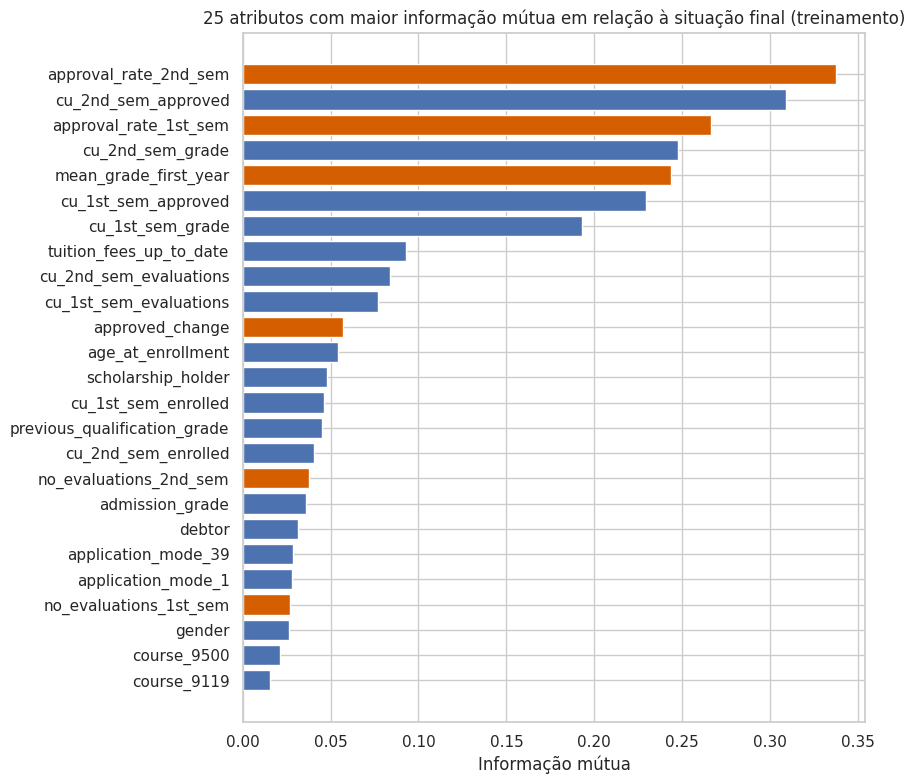

In [43]:
mi = mutual_info_classif(X_train_oh, y_train, random_state=RANDOM_STATE,
                         discrete_features=[c not in ATRIBUTOS_NUMERICOS_PROC for c in X_train_oh.columns])
mi = pd.Series(mi, index=X_train_oh.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
top = mi.head(25)[::-1]
cores = ["#D55E00" if c in ATRIBUTOS_DERIVADOS + ["no_evaluations_1st_sem", "no_evaluations_2nd_sem"]
         else "#4C72B0" for c in top.index]
ax.barh(top.index, top.values, color=cores)
ax.set_title("25 atributos com maior informação mútua em relação à situação final (treinamento)")
ax.set_xlabel("Informação mútua")
plt.tight_layout()
plt.show()

In [44]:
# Valores numéricos dos atributos com maior informação mútua, como apoio à figura
mi.head(12).round(3).to_frame("informação_mútua")

,informação_mútua
approval_rate_2nd_sem,0.337
cu_2nd_sem_approved,0.309
approval_rate_1st_sem,0.266
cu_2nd_sem_grade,0.247
mean_grade_first_year,0.243
cu_1st_sem_approved,0.229
cu_1st_sem_grade,0.193
tuition_fees_up_to_date,0.093
cu_2nd_sem_evaluations,0.084
cu_1st_sem_evaluations,0.077


O ranking é compatível com H1 e com H2. Os sete atributos de maior informação mútua são todos de desempenho acadêmico. A taxa de aprovação do segundo semestre, atributo derivado, ocupa o primeiro lugar, seguida pelo número de aprovações do segundo semestre e pela taxa de aprovação do primeiro. A regularidade das mensalidades é o primeiro atributo não acadêmico a aparecer, na oitava posição. Mais abaixo vêm a idade, a bolsa de estudos, a condição de devedor e o sexo. Os atributos derivados (em laranja) situam-se entre os mais informativos, e os indicadores de ausência de avaliação também figuram entre os 25 primeiros, o que indica que o tratamento adotado na decisão D1 preservou informação.

Há três cuidados na leitura. A informação mútua é univariada e não desconta a redundância entre atributos, de modo que atributos quase equivalentes aparecem lado a lado. As colunas one-hot de cursos e de vias de ingresso aparecem com valores modestos porque a codificação distribui a informação de um atributo nominal entre muitas colunas, embora o atributo agregado tenha se mostrado associado à evasão na seção 3.2.7. Por fim, a medida descreve dependência estatística no treinamento, e não importância causal nem desempenho de um modelo.

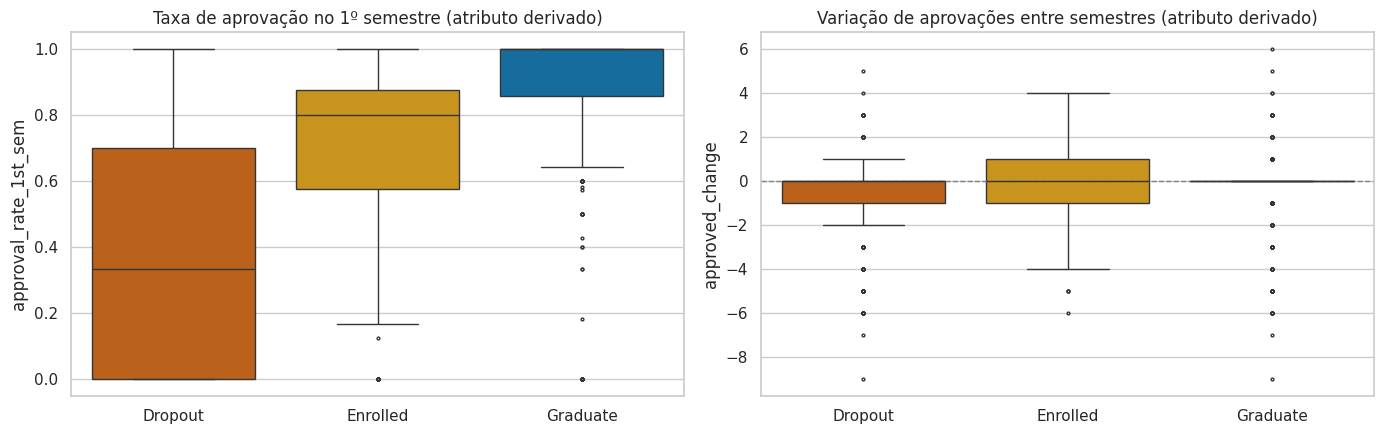

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
treino_plot = X_train_oh.assign(target=y_train.map(MAPA_ALVO_INVERSO))

sns.boxplot(data=treino_plot, x="target", y="approval_rate_1st_sem", order=CLASS_ORDER, hue="target",
            hue_order=CLASS_ORDER, palette=CLASS_COLORS, legend=False, ax=axes[0], fliersize=2)
axes[0].set_title("Taxa de aprovação no 1º semestre (atributo derivado)")
axes[0].set_xlabel("")

sns.boxplot(data=treino_plot, x="target", y="approved_change", order=CLASS_ORDER, hue="target",
            hue_order=CLASS_ORDER, palette=CLASS_COLORS, legend=False, ax=axes[1], fliersize=2)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Variação de aprovações entre semestres (atributo derivado)")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

In [46]:
# Quartis dos dois atributos derivados por situação final (treinamento), como apoio numérico à figura
treino_plot.groupby("target")[["approval_rate_1st_sem", "approved_change"]].quantile([0.25, 0.5, 0.75]).unstack().reindex(CLASS_ORDER).round(2)

approval_rate_1st_sem             approved_change          
                          0.25  0.50  0.75            0.25 0.50 0.75
target                                                              
Dropout                   0.00  0.33  0.70            -1.0  0.0  0.0
Enrolled                  0.58  0.80  0.88            -1.0  0.0  1.0
Graduate                  0.86  1.00  1.00             0.0  0.0  0.0

Os atributos derivados separam as classes de modo coerente com H1. No treinamento, a taxa de aprovação do primeiro semestre tem mediana 1,00 entre os concluintes, 0,80 entre os matriculados e 0,33 entre os evadidos, cuja distribuição se espalha por toda a faixa de 0 a 1. A variação de aprovações entre semestres tem mediana zero nas três classes. Entre os concluintes, os quartis também são zero, o que indica desempenho estável. Entre os evadidos, o primeiro quartil é -1, refletindo estudantes cujo número de aprovações caiu no segundo semestre. Os matriculados têm o maior intervalo interquartil (de -1 a 1), em linha com a heterogeneidade prevista em H4.

O cuidado é que a taxa de aprovação igual a zero inclui os registros sem inscrição do curso 171, e que os dois atributos são combinações de atributos originais, de modo que não trazem informação independente deles.

## 4.9 Verificações antes e depois e síntese das visões

A tabela a seguir resume as visões produzidas e sua indicação. As duas compartilham a mesma partição estratificada de treinamento e teste e a mesma codificação da variável alvo.

| Visão | Transformações aplicadas | Indicação |
|---|---|---|
| `onehot` | Indicadores de ausência de avaliação, atributos derivados, agrupamento de categorias raras e one-hot dos nominais | Métodos que não dependem da escala dos atributos, como os baseados em árvores |
| `standardized` | Visão `onehot` com padronização z-score dos numéricos e do ordinal | Métodos sensíveis à escala, como os lineares e os baseados em distância |

As células seguintes conferem dimensões, ausências, proporção das classes e integridade das linhas em cada etapa, da base de origem às visões finais.

In [47]:
visoes = {
    "onehot": (X_train_oh, X_test_oh),
    "standardized": (X_train_std, X_test_std),
}

resumo_visoes = pd.DataFrame({
    nome: {"linhas_treino": tr.shape[0], "linhas_teste": te.shape[0], "colunas": tr.shape[1],
           "valores_ausentes": int(tr.isna().sum().sum() + te.isna().sum().sum())}
    for nome, (tr, te) in visoes.items()
}).T
resumo_visoes

,linhas_treino,linhas_teste,colunas,valores_ausentes
onehot,3539,885,112,0
standardized,3539,885,112,0


In [48]:
def resumir_etapa(dados, alvo):
    """Resume uma etapa do pré-processamento por dimensões, ausências e proporção das classes."""
    proporcoes = (alvo.value_counts(normalize=True) * 100).round(1)
    resumo = {"linhas": dados.shape[0], "colunas": dados.shape[1], "valores_ausentes": int(dados.isna().sum().sum())}
    resumo.update({f"%_{classe}": proporcoes[classe] for classe in CLASS_ORDER})
    return resumo


alvo_treino = y_train.map(MAPA_ALVO_INVERSO)
alvo_teste = y_test.map(MAPA_ALVO_INVERSO)
verificacao = pd.DataFrame({
    "origem (df_raw)": resumir_etapa(df_raw.drop(columns="Target"), df_raw["Target"]),
    "com derivados (df_proc)": resumir_etapa(df_proc.drop(columns=[TARGET, "target_encoded"]), df_proc[TARGET]),
    "onehot treino": resumir_etapa(X_train_oh, alvo_treino),
    "onehot teste": resumir_etapa(X_test_oh, alvo_teste),
    "standardized treino": resumir_etapa(X_train_std, alvo_treino),
    "standardized teste": resumir_etapa(X_test_std, alvo_teste),
}).T
colunas_inteiras = ["linhas", "colunas", "valores_ausentes"]
verificacao[colunas_inteiras] = verificacao[colunas_inteiras].astype(int)

# Integridade das linhas: nenhuma linha perdida, duplicada ou presente nas duas partições
indices_treino, indices_teste = set(X_train_oh.index), set(X_test_oh.index)
assert indices_treino.isdisjoint(indices_teste)
assert indices_treino | indices_teste == set(df_raw.index)
assert X_train_std.index.equals(X_train_oh.index) and X_test_std.index.equals(X_test_oh.index)
# Os atributos não escalonados são idênticos nas duas visões
colunas_nao_escalonadas = [c for c in X_train_oh.columns if c not in COLUNAS_ESCALA]
assert X_train_std[colunas_nao_escalonadas].equals(X_train_oh[colunas_nao_escalonadas])
print("Integridade das linhas verificada: partições disjuntas e união igual à base de origem.")
verificacao

Integridade das linhas verificada: partições disjuntas e união igual à base de origem.


,linhas,colunas,valores_ausentes,%_Dropout,%_Enrolled,%_Graduate
origem (df_raw),4424,36,0,32.1,17.9,49.9
com derivados (df_proc),4424,42,0,32.1,17.9,49.9
onehot treino,3539,112,0,32.1,17.9,49.9
onehot teste,885,112,0,32.1,18.0,49.9
standardized treino,3539,112,0,32.1,17.9,49.9
standardized teste,885,112,0,32.1,18.0,49.9


Nenhuma linha foi perdida ou duplicada. As 4424 linhas de origem estão distribuídas em 3539 de treinamento e 885 de teste, sem interseção. As colunas passam de 36 atributos de origem para 42 com os derivados e para 112 após o one-hot. Não há valores ausentes em nenhuma etapa, e a proporção das três classes é preservada nas duas partições.

## 4.10 Registro das decisões

| Decisão | Problema observado e evidência | Alternativas consideradas | Escolha | Verificação e limitação |
|---|---|---|---|---|
| D1 | Nota zero com dois significados (tabela de zeros por semestre e perfil dos registros sem inscrição, seção 3.1.3) | Manter como está, tratar como ausente, manter com indicador | Manter o zero e criar indicadores de ausência de avaliação | Comparação de médias por classe na seção 4.1. O indicador não separa a lacuna do curso 171 da ausência real |
| D2 | Proporção elevada de valores discrepantes pelo critério IQR (tabela e diagramas de caixa, seção 3.2.3) | Manter, remover linhas com valores discrepantes | Manter | Comparação de linhas e classes na seção 3.2.3. Atributos de cauda longa seguem sensíveis à escala |
| D3 | Nominais com muitas categorias raras (tabela de cardinalidade, seção 3.1.5) | One-hot direto, agrupamento a 1% antes do one-hot | Agrupamento a 1% aprendido no treinamento | Comparação de colunas na seção 4.5. A categoria `other` reúne grupos heterogêneos |
| D4 | Escalas muito distintas entre numéricos (histogramas e resumo estatístico, seções 3.2.2 e 3.1.4) | Manter escala, padronização, min-max | Visão base sem escala e visão padronizada | Comparação de quantis na seção 4.6. Sem modelo, o efeito preditivo da escala não é medido |

# 5. Finalização e download da base processada

Cada visão é salva em arquivos CSV separados para treinamento e teste, já com a variável alvo codificada anexada como última coluna. Também é salvo o conjunto completo pré-processado (antes do particionamento), para o caso de se desejar outra estratégia de validação, e um dicionário de dados com o mapa de nomes e a codificação do alvo. Todos os arquivos são compactados em um único arquivo zip, cujo download é oferecido automaticamente no Colab.

In [49]:
PASTA_SAIDA = "dados_processados"
os.makedirs(PASTA_SAIDA, exist_ok=True)

arquivos_gerados = []

# Visões particionadas
for nome, (tr, te) in visoes.items():
    for particao, X_part, y_part in (("train", tr, y_train), ("test", te, y_test)):
        caminho = os.path.join(PASTA_SAIDA, f"{nome}_{particao}.csv")
        X_part.assign(target=y_part.values).to_csv(caminho, index=False)
        arquivos_gerados.append(caminho)

# Conjunto completo pré-processado, antes do particionamento e da codificação one-hot
caminho_completo = os.path.join(PASTA_SAIDA, "dataset_preprocessado_completo.csv")
df_proc.to_csv(caminho_completo, index=False)
arquivos_gerados.append(caminho_completo)

# Dicionário de dados
caminho_dicionario = os.path.join(PASTA_SAIDA, "dicionario_de_dados.csv")
dicionario = pd.DataFrame({"nome_original": list(mapa_nomes.keys()), "nome_padronizado": list(mapa_nomes.values())})
dicionario.to_csv(caminho_dicionario, index=False)
arquivos_gerados.append(caminho_dicionario)

caminho_alvo = os.path.join(PASTA_SAIDA, "codificacao_alvo.csv")
pd.DataFrame({"classe": MAPA_ALVO.keys(), "codigo": MAPA_ALVO.values()}).to_csv(caminho_alvo, index=False)
arquivos_gerados.append(caminho_alvo)

# Compactação
ARQUIVO_ZIP = "dados_processados.zip"
with zipfile.ZipFile(ARQUIVO_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    for caminho in arquivos_gerados:
        zf.write(caminho)

print("Arquivos gerados:")
for caminho in arquivos_gerados:
    print(f"  {caminho} ({os.path.getsize(caminho) / 1024:.0f} KB)")
print(f"\nArquivo compactado: {ARQUIVO_ZIP} ({os.path.getsize(ARQUIVO_ZIP) / 1024:.0f} KB)")

Arquivos gerados:
  dados_processados/onehot_train.csv (973 KB)
  dados_processados/onehot_test.csv (245 KB)
  dados_processados/standardized_train.csv (2192 KB)
  dados_processados/standardized_test.csv (550 KB)
  dados_processados/dataset_preprocessado_completo.csv (670 KB)
  dados_processados/dicionario_de_dados.csv (2 KB)
  dados_processados/codificacao_alvo.csv (0 KB)

Arquivo compactado: dados_processados.zip (621 KB)


In [50]:
# Download automático no Google Colab. Fora do Colab, o arquivo zip permanece no diretório de trabalho.
try:
    from google.colab import files
    files.download(ARQUIVO_ZIP)
except ImportError:
    print(f"Ambiente fora do Colab. O arquivo {ARQUIVO_ZIP} está disponível no diretório de trabalho.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 6. Considerações finais

## 6.1 Respostas às hipóteses

**H1, desempenho no primeiro ano.** Os dados são compatíveis com a hipótese. A mediana de aprovações é de 6 por semestre entre os concluintes e de 2 e 0 entre os evadidos, e os sete atributos de maior informação mútua com a situação final são de desempenho acadêmico (seções 3.2.4 e 4.8). Permanece incerto quanto dessa diferença reflete desempenho e quanto reflete não participação, pois parte das notas zero marca ausência de avaliação, e os 180 registros do curso 171 não têm dados curriculares. Como o desempenho só é conhecido ao fim de cada semestre, ele não serve a uma identificação de risco no momento do ingresso.

**H2, fatores financeiros.** Os dados são compatíveis com a hipótese. A evasão é de 86,6% entre os estudantes com mensalidades em atraso, contra 24,7% entre os que estão em dia, e de 62,0% entre os devedores, contra 28,3%. Entre os bolsistas, a evasão é de 12,2% (seção 3.2.5). Permanece incerta a direção da associação. A base não informa quando esses atributos foram medidos, e o atraso no pagamento pode ser consequência da decisão de sair.

**H3, perfil demográfico.** Os dados são compatíveis com a hipótese. A evasão passa de 21,0% entre os que ingressam com 17 a 19 anos para 57,6% na faixa de 25 a 29 anos e permanece acima de 50% nas faixas seguintes. Ela é de 55,4% na via de ingresso de maiores de 23 anos, contra 20,2% na primeira fase do concurso geral, e de 42,9% no regime noturno, contra 30,8% no diurno (seções 3.2.5 a 3.2.7). Permanece incerto o peso de cada fator, pois idade, via de ingresso, regime e curso se sobrepõem, e a análise é univariada.

**H4, dificuldade da classe Enrolled.** A hipótese não foi testada diretamente, pois exigiria treinar e avaliar um modelo. A evidência disponível é indireta. As distribuições de desempenho da classe **Enrolled** ficam entre as das outras duas e se sobrepõem a ambas (seção 3.2.4), e essa classe tem o maior intervalo interquartil na variação de aprovações (seção 4.8). A hipótese permanece em aberto.

## 6.2 Limitações

Os dados provêm de uma única instituição portuguesa e de um período encerrado em 2018/2019, o que restringe a generalização. A base já chegou pré-processada pelos autores, sem registro dos casos removidos. Os códigos das categorias dependem da documentação original. As unidades curriculares de um curso inteiro não estão registradas. Os indicadores macroeconômicos assumem apenas cerca de dez valores distintos e funcionam como marcadores do ano de ingresso. A análise é descritiva e univariada, sem testes de hipótese nem controle de fatores sobrepostos, de modo que nenhuma das associações deve ser lida como causal. A análise exploratória usou a base completa, antes da partição, o que é adequado à descrição, mas significa que as decisões de pré-processamento foram informadas também pelas linhas que compõem o teste. Os parâmetros das transformações, por sua vez, foram aprendidos apenas no treinamento.

## 6.3 Próximos passos

O passo seguinte é treinar e comparar modelos de classificação sobre as visões geradas, com validação cruzada estratificada no treinamento e métricas sensíveis às classes minoritárias, como F1 macro e a matriz de confusão, o que permitirá testar H4. Convém avaliar o tratamento dos registros do curso 171, comparando resultados com e sem eles. A redundância entre atributos de desempenho pode orientar uma seleção de atributos. Para uso institucional, vale ainda comparar um modelo restrito às informações do ingresso com outro que inclua o primeiro semestre, a fim de medir quanto da capacidade de identificação depende de informação que só surge quando parte da evasão já ocorreu.

# 7. Referências

Realinho, V., Machado, J., Baptista, L., e Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146

Realinho, V., Vieira Martins, M., Machado, J., e Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [conjunto de dados]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

O código utiliza as bibliotecas pandas, NumPy, scikit-learn, Matplotlib e seaborn, nas versões listadas na seção 2. Os nomes dos cursos e das vias de ingresso foram transcritos da documentação do conjunto de dados.

# 8. Declaração de uso de IA

Foi utilizado o assistente de IA Claude (Anthropic) como apoio à programação (estrutura do código, funções, gráficos e correção de erros). O autor executou o notebook, conferiu os valores citados contra as saídas e responde integralmente pelo código, pelas interpretações e pelas conclusões apresentadas.

# 9. Checklist de entrega

| Item | Localização no notebook | Observação |
|---|---|---|
| 1. Problema, unidade de observação, perguntas e objetivo analítico | Seções 1.1 a 1.3 | Hipóteses H1 a H4 |
| 2. Origem, versão e período, condições de uso, recortes e dicionário | Seções 1.4 e 1.5 | Nenhum recorte foi aplicado |
| 3. Dimensões, tipos, inspeção inicial e estatísticas | Seções 3.1.1, 3.1.2, 3.1.4 e 3.1.5 | Frequências para binários e nominais em 3.1.5 |
| 4. Ausências, duplicidades, inconsistências e valores extremos | Seções 3.1.3 e 3.2.3 | Extremos distinguidos de erros de registro em 3.2.3 |
| 5. Distribuições e relações relevantes, incluindo classes | Seções 3.2.1 a 3.2.8 | Seleção de gráficos justificada em 3.2 |
| 6. Interpretações após as figuras, com evidências e limites | Texto após cada figura das seções 3.2 e 4.8 | Percentuais citados constam das tabelas de apoio |
| 7. Decisões D1 a D3 e comparação efetiva entre alternativas | D1 em 4.1, D2 em 3.2.3, D3 em 4.5, D4 em 4.6, resumo em 4.10 | Comparações com medida em D1, D2, D3 e D4 |
| 8. Transformações adequadas ou manutenção justificada, com verificações antes e depois | Seções 4.1 a 4.7 e 4.9 | Transformações não aplicadas justificadas em 4.7 |
| 9. Divisão dos dados e prevenção de vazamento | Seções 4.4 a 4.6 | Parâmetros aprendidos apenas no treinamento |
| 10. Respostas às perguntas, limitações e próximos passos | Seções 6.1 a 6.3 | H4 não testada, por depender de modelagem |
| 11. Template adaptado, dados disponíveis, dependências, execução e link do Colab | Seção 2 e entrega no ambiente da disciplina | Dados obtidos da pasta compartilhada do Google Drive. Versões das bibliotecas listadas na seção 2 |